# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Kadek Nathania Gavrila Astika | 5054251050 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed dengan tf.keras.utils.set_random_seed(42).
# Cek apakah GPU tersedia dengan tf.config.list_physical_devices("GPU").

import os
import time
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # sembunyikan log informasi TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Random seed agar hasil eksperimen dapat direproduksi
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version :", tf.__version__)
print("Keras version      :", keras.__version__)

# Cek ketersediaan GPU
gpus = tf.config.list_physical_devices("GPU")
print("GPU tersedia       :", gpus if gpus else "Tidak ada (training berjalan di CPU)")

TensorFlow version : 2.21.0
Keras version      : 3.13.2
GPU tersedia       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

# Fungsi kecil untuk mencari file dataset di beberapa lokasi umum (lokal / Colab / Kaggle)
def find_file(filename):
    candidates = [
        filename,
        os.path.join("data", filename),
        os.path.join("/content", filename),
        os.path.join("/kaggle/input/fashionmnist", filename),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"{filename} tidak ditemukan. Letakkan file di folder yang sama dengan notebook.")

train_df = pd.read_csv(find_file("fashion-mnist_train.csv"))
test_df = pd.read_csv(find_file("fashion-mnist_test.csv"))

print("Ukuran data train :", train_df.shape, "-> (jumlah gambar, 1 label + 784 piksel)")
print("Ukuran data test  :", test_df.shape, "-> (jumlah gambar, 1 label + 784 piksel)")
print("Total gambar      :", len(train_df) + len(test_df))
train_df.head()

Ukuran data train : (60000, 785) -> (jumlah gambar, 1 label + 784 piksel)
Ukuran data test  : (10000, 785) -> (jumlah gambar, 1 label + 784 piksel)
Total gambar      : 70000


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Pemetaan label:
  0 -> T-shirt/top
  1 -> Trouser
  2 -> Pullover
  3 -> Dress
  4 -> Coat
  5 -> Sandal
  6 -> Shirt
  7 -> Sneaker
  8 -> Bag
  9 -> Ankle boot


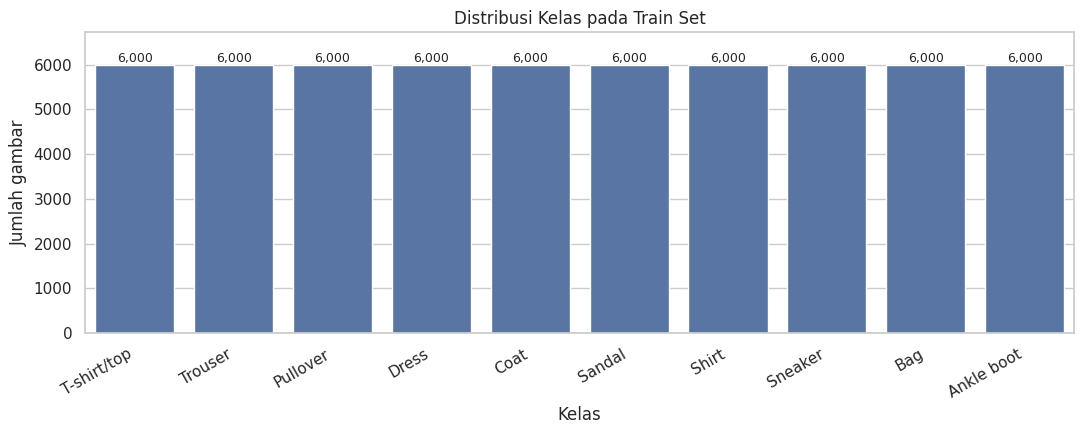

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
label_map = {i: name for i, name in enumerate(class_names)}
print("Pemetaan label:")
for k, v in label_map.items():
    print(f"  {k} -> {v}")

# Distribusi kelas pada train set
class_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(11, 4.5))
ax = sns.barplot(x=[label_map[i] for i in class_counts.index], y=class_counts.values, color="#4C72B0")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.title("Distribusi Kelas pada Train Set")
plt.xlabel("Kelas")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, class_counts.max() * 1.12)
plt.tight_layout()
plt.show()

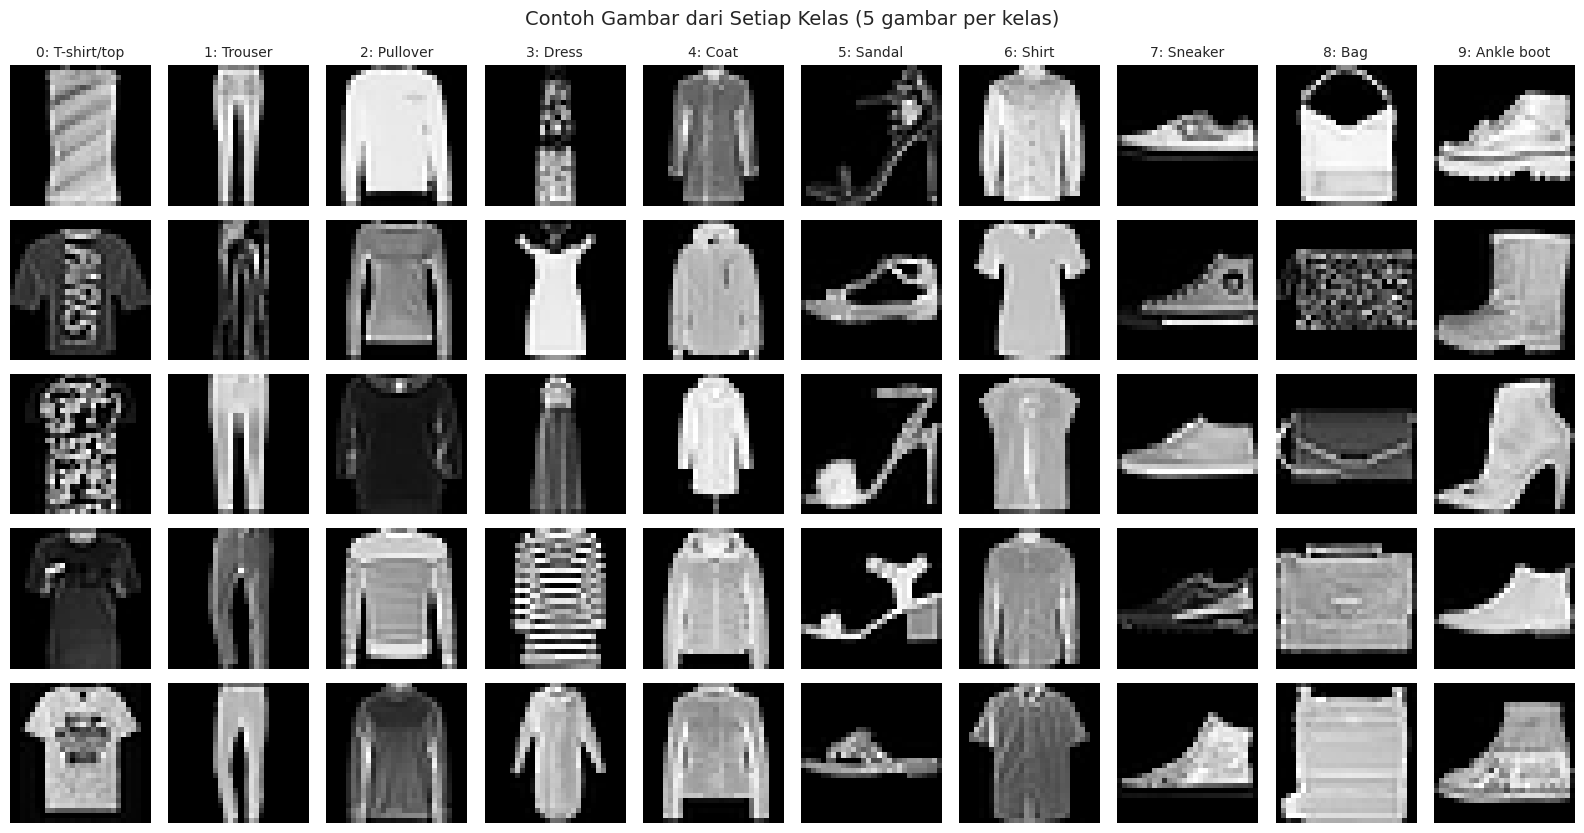

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

# Grid 10 kelas x 5 gambar: setiap KOLOM adalah satu kelas, setiap kolom berisi 5 contoh gambar
n_samples = 5
fig, axes = plt.subplots(n_samples, 10, figsize=(16, 8.5))
for c in range(10):
    samples = train_df[train_df["label"] == c].sample(n_samples, random_state=SEED)
    for r in range(n_samples):
        img = samples.iloc[r, 1:].values.reshape(28, 28)
        axes[r, c].imshow(img, cmap="gray")
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"{c}: {class_names[c]}", fontsize=10)
plt.suptitle("Contoh Gambar dari Setiap Kelas (5 gambar per kelas)", fontsize=14)
plt.tight_layout()
plt.show()

**Kelas yang secara visual terlihat mirip:**

Dari grid contoh gambar di atas, beberapa kelompok kelas terlihat mirip secara visual:

- **T-shirt/top, Shirt, Pullover, dan Coat**: keempatnya adalah pakaian atasan dengan siluet badan dan dua lengan. Pada resolusi 28×28, perbedaan utamanya (kerah, kancing, resleting, ketebalan bahan, panjang lengan) hanya berupa beberapa piksel sehingga sulit dibedakan. **Shirt** adalah kelas yang paling ambigu karena ada yang berlengan pendek (mirip T-shirt/top) dan ada yang berlengan panjang (mirip Pullover/Coat).
- **Pullover dan Coat**: sama-sama berlengan panjang dengan bentuk badan yang hampir identik; pembedanya hanya bukaan/resleting di tengah dan panjang badan.
- **Dress dengan T-shirt/top, Shirt, atau Coat panjang**: Dress tanpa lengan mirip T-shirt panjang, sedangkan Dress berlengan panjang mirip Coat.
- **Sneaker dan Ankle boot**: sama-sama sepatu menghadap ke kiri; pembedanya hanya tinggi bagian pergelangan kaki. **Sandal** lebih mudah dibedakan karena bentuknya berongga (tali-tali), walaupun sandal yang tertutup bisa mirip Sneaker.

Sebaliknya, **Trouser** dan **Bag** memiliki bentuk yang sangat khas (dua kaki memanjang dan bentuk kotak dengan pegangan) sehingga diperkirakan paling mudah dikenali.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

### EDA 1 - Kualitas data: missing value, duplikat, tipe data, dan rentang nilai piksel

In [5]:
pixel_cols = [c for c in train_df.columns if c != "label"]

for name, df in [("Train", train_df), ("Test", test_df)]:
    print(f"=== {name} set ===")
    print("Jumlah missing value   :", int(df.isnull().sum().sum()))
    print("Jumlah baris duplikat  :", int(df.duplicated().sum()))
    print("Tipe data kolom        :", df.dtypes.unique().tolist())
    print("Nilai piksel min / max :", int(df[pixel_cols].values.min()), "/", int(df[pixel_cols].values.max()))
    print("Label unik             :", sorted(df["label"].unique().tolist()))
    print()

=== Train set ===
Jumlah missing value   : 0
Jumlah baris duplikat  : 43
Tipe data kolom        : [dtype('int64')]
Nilai piksel min / max : 0 / 255
Label unik             : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

=== Test set ===
Jumlah missing value   : 0
Jumlah baris duplikat  : 1
Tipe data kolom        : [dtype('int64')]
Nilai piksel min / max : 0 / 255
Label unik             : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]



### EDA 2 - Perbandingan distribusi kelas train set vs test set

,Train,Test,Train (%),Test (%)
T-shirt/top,6000,1000,10.0,10.0
Trouser,6000,1000,10.0,10.0
Pullover,6000,1000,10.0,10.0
Dress,6000,1000,10.0,10.0
Coat,6000,1000,10.0,10.0
Sandal,6000,1000,10.0,10.0
Shirt,6000,1000,10.0,10.0
Sneaker,6000,1000,10.0,10.0
Bag,6000,1000,10.0,10.0
Ankle boot,6000,1000,10.0,10.0


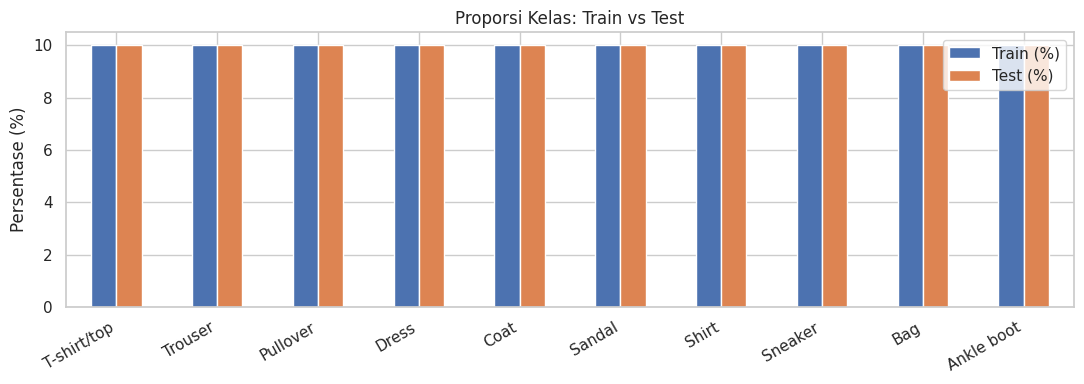

In [6]:
dist = pd.DataFrame({
    "Train": train_df["label"].value_counts().sort_index(),
    "Test": test_df["label"].value_counts().sort_index(),
})
dist.index = class_names
dist["Train (%)"] = (dist["Train"] / dist["Train"].sum() * 100).round(2)
dist["Test (%)"] = (dist["Test"] / dist["Test"].sum() * 100).round(2)
display(dist)

dist[["Train (%)", "Test (%)"]].plot(kind="bar", figsize=(11, 4), color=["#4C72B0", "#DD8452"])
plt.title("Proporsi Kelas: Train vs Test")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### EDA 3 - Distribusi intensitas piksel

Proporsi piksel bernilai 0 (background hitam): 50.18%
Rata-rata intensitas piksel: 72.96 | Standar deviasi: 89.97


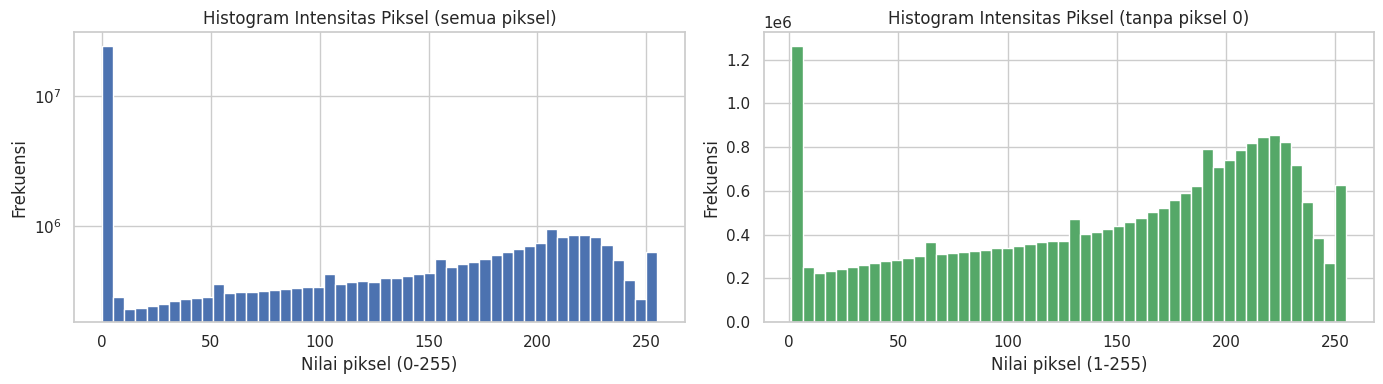

In [7]:
pixels = train_df[pixel_cols].values
zero_ratio = (pixels == 0).mean() * 100
print(f"Proporsi piksel bernilai 0 (background hitam): {zero_ratio:.2f}%")
print(f"Rata-rata intensitas piksel: {pixels.mean():.2f} | Standar deviasi: {pixels.std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(pixels.ravel(), bins=50, color="#4C72B0")
axes[0].set_title("Histogram Intensitas Piksel (semua piksel)")
axes[0].set_xlabel("Nilai piksel (0-255)")
axes[0].set_ylabel("Frekuensi")
axes[0].set_yscale("log")

nonzero = pixels[pixels > 0]
axes[1].hist(nonzero, bins=50, color="#55A868")
axes[1].set_title("Histogram Intensitas Piksel (tanpa piksel 0)")
axes[1].set_xlabel("Nilai piksel (1-255)")
axes[1].set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

### EDA 4 - Rata-rata kecerahan gambar per kelas

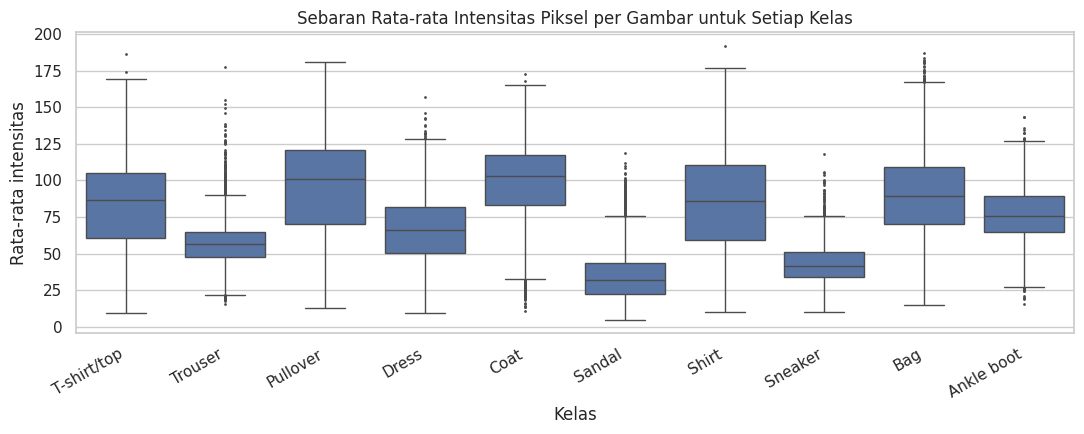

,mean,std
Kelas,,
T-shirt/top,82.88,28.86
Trouser,56.75,14.58
Pullover,95.72,32.58
Dress,66.20,21.59
Coat,98.16,26.51
Sandal,34.87,15.90
Shirt,85.12,32.81
Sneaker,42.84,12.77
Bag,90.04,28.59


In [8]:
brightness = pd.DataFrame({
    "Kelas": train_df["label"].map(label_map),
    "Rata-rata intensitas": pixels.mean(axis=1),
})
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=brightness, x="Kelas", y="Rata-rata intensitas", order=class_names, color="#4C72B0", fliersize=1)
plt.title("Sebaran Rata-rata Intensitas Piksel per Gambar untuk Setiap Kelas")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

display(brightness.groupby("Kelas")["Rata-rata intensitas"].agg(["mean", "std"]).loc[class_names].round(2))

### EDA 5 - Gambar rata-rata setiap kelas dan kemiripan antar kelas

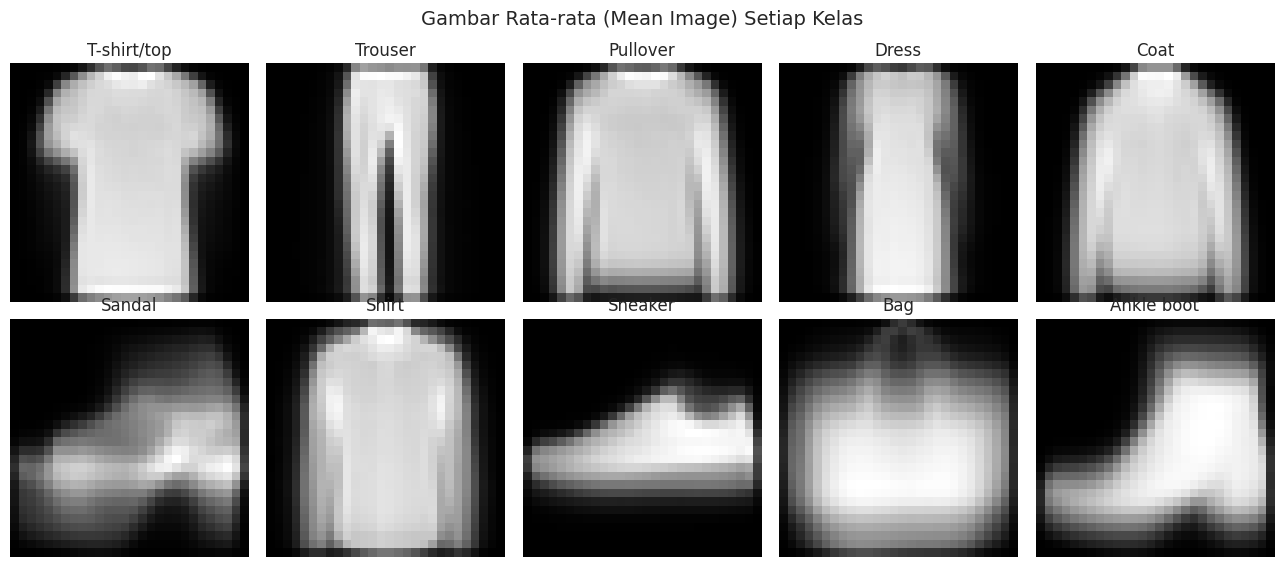

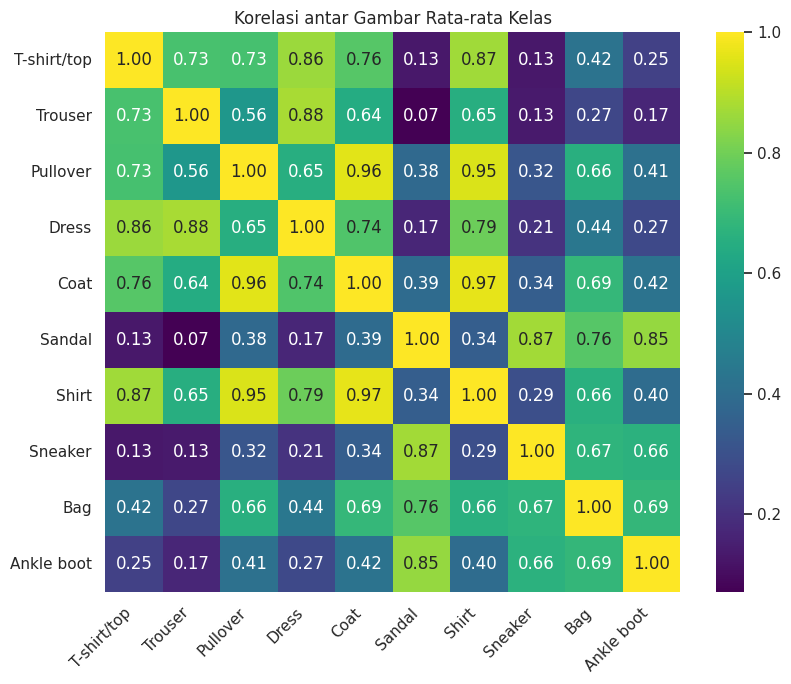

5 pasangan kelas dengan gambar rata-rata paling mirip:
  Coat         - Shirt       : korelasi = 0.967
  Pullover     - Coat        : korelasi = 0.959
  Pullover     - Shirt       : korelasi = 0.948
  Trouser      - Dress       : korelasi = 0.880
  Sandal       - Sneaker     : korelasi = 0.872


In [9]:
# Gambar rata-rata (mean image) setiap kelas
mean_images = np.stack([train_df[train_df["label"] == c][pixel_cols].values.mean(axis=0) for c in range(10)])

fig, axes = plt.subplots(2, 5, figsize=(13, 5.8))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(mean_images[c].reshape(28, 28), cmap="gray")
    ax.set_title(class_names[c])
    ax.axis("off")
plt.suptitle("Gambar Rata-rata (Mean Image) Setiap Kelas", fontsize=14)
plt.tight_layout()
plt.show()

# Korelasi antar gambar rata-rata -> indikasi kelas yang mirip pada level piksel
corr = np.corrcoef(mean_images)
plt.figure(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", xticklabels=class_names, yticklabels=class_names)
plt.title("Korelasi antar Gambar Rata-rata Kelas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

pairs = [(corr[i, j], class_names[i], class_names[j]) for i in range(10) for j in range(i + 1, 10)]
print("5 pasangan kelas dengan gambar rata-rata paling mirip:")
for v, a, b in sorted(pairs, reverse=True)[:5]:
    print(f"  {a:12s} - {b:12s}: korelasi = {v:.3f}")

### EDA 6 - Proyeksi PCA 2 dimensi

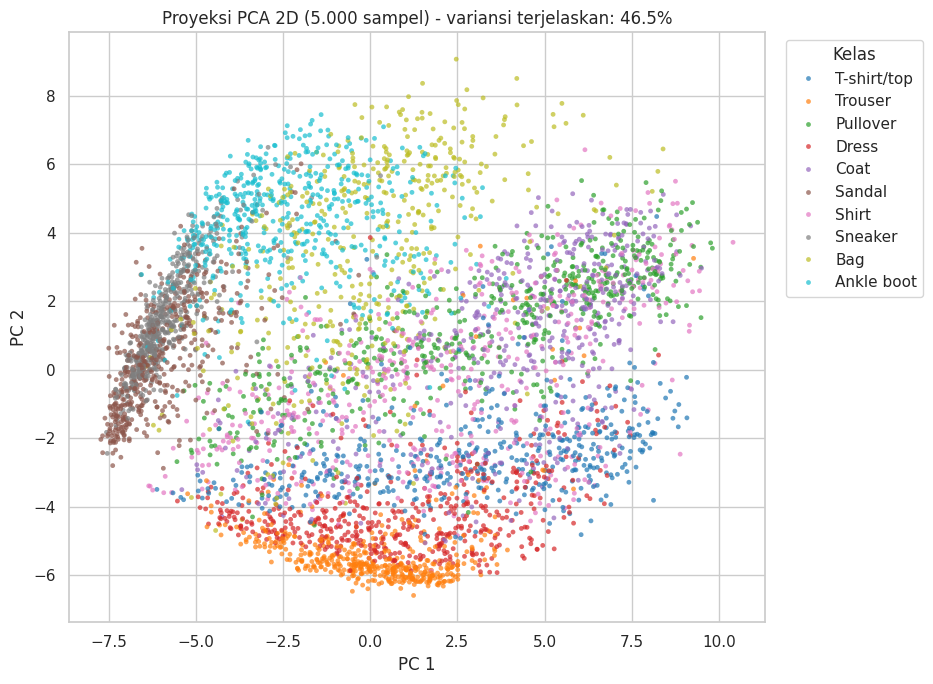

In [10]:
# Proyeksi 784 dimensi piksel ke 2 dimensi untuk melihat seberapa terpisah setiap kelas
sample = train_df.sample(5000, random_state=SEED)
pca = PCA(n_components=2, random_state=SEED)
proj = pca.fit_transform(sample[pixel_cols].values / 255.0)

plt.figure(figsize=(9.5, 7))
sns.scatterplot(x=proj[:, 0], y=proj[:, 1], hue=sample["label"].map(label_map), hue_order=class_names,
                palette="tab10", s=12, alpha=0.7, linewidth=0)
plt.title(f"Proyeksi PCA 2D (5.000 sampel) - variansi terjelaskan: {pca.explained_variance_ratio_.sum() * 100:.1f}%")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title="Kelas", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Ringkasan temuan EDA

1. **Kualitas data baik.** Tidak ada missing value pada train (60.000 gambar) maupun test (10.000 gambar), semua kolom bertipe integer, dan nilai piksel berada pada rentang 0–255. Terdapat 43 baris duplikat pada train set dan 1 pada test set (0,07% data); jumlahnya sangat kecil sehingga tidak dihapus dan tidak berpengaruh berarti terhadap pelatihan.
2. **Kelas seimbang sempurna.** Setiap kelas memiliki tepat 6.000 gambar pada train set dan 1.000 gambar pada test set (masing-masing 10%). Karena itu tidak diperlukan penanganan imbalance, accuracy menjadi metrik yang valid, dan nilai macro average akan sama dengan weighted average.
3. **Sekitar separuh piksel adalah background.** 50,18% piksel bernilai 0 (latar hitam), dengan rata-rata intensitas 72,96 dan standar deviasi 89,97. Rentang 0–255 ini perlu dinormalisasi ke 0–1 agar proses optimasi lebih stabil.
4. **Kecerahan berbeda antar kelas.** Coat (98,2), Pullover (95,7), dan Bag (90,0) memiliki rata-rata intensitas tertinggi karena objeknya menutupi area gambar yang luas, sedangkan Sandal (34,9) dan Sneaker (42,8) paling rendah karena objeknya kecil/berongga. Luas area objek sudah menjadi petunjuk awal bagi model, tetapi sebarannya saling tumpang tindih sehingga tidak cukup untuk membedakan kelas.
5. **Gambar rata-rata mengonfirmasi kelas yang mirip.** Korelasi antar gambar rata-rata paling tinggi pada Coat–Shirt (0,967), Pullover–Coat (0,959), dan Pullover–Shirt (0,948), disusul Trouser–Dress (0,880) dan Sandal–Sneaker (0,872). Artinya pada level piksel, kelompok pakaian atasan berlengan panjang hampir tidak dapat dibedakan dari bentuk globalnya saja.
6. **Proyeksi PCA.** Dua komponen utama hanya menjelaskan 46,5% variansi. Trouser serta kelompok alas kaki (Sandal, Sneaker, Ankle boot) membentuk kelompok yang relatif terpisah, sedangkan Pullover, Coat, dan Shirt bertumpuk di area yang sama. Ini menunjukkan bahwa pemisahan kelas atasan membutuhkan fitur non-linear dan detail lokal, yang menjadi alasan penggunaan CNN.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [11]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns=["label"]).values

y_test = test_df["label"].values
X_test = test_df.drop(columns=["label"]).values

print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test      :", X_test.shape, "| y_test      :", y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test      : (10000, 784) | y_test      : (10000,)


In [12]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print(f"Rentang nilai train setelah normalisasi: {X_train_full.min():.1f} - {X_train_full.max():.1f}")
print(f"Rentang nilai test setelah normalisasi : {X_test.min():.1f} - {X_test.max():.1f}")

Rentang nilai train setelah normalisasi: 0.0 - 1.0
Rentang nilai test setelah normalisasi : 0.0 - 1.0


In [13]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED
)

print("Train set     :", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set      :", X_test.shape, y_test.shape)

# Memastikan proporsi kelas tetap seimbang setelah stratified split
print("\nJumlah gambar per kelas:")
display(pd.DataFrame({
    "Train": np.bincount(y_train),
    "Validation": np.bincount(y_val),
    "Test": np.bincount(y_test),
}, index=class_names))

Train set     : (54000, 784) (54000,)
Validation set: (6000, 784) (6000,)
Test set      : (10000, 784) (10000,)

Jumlah gambar per kelas:


,Train,Validation,Test
T-shirt/top,5400,600,1000
Trouser,5400,600,1000
Pullover,5400,600,1000
Dress,5400,600,1000
Coat,5400,600,1000
Sandal,5400,600,1000
Shirt,5400,600,1000
Sneaker,5400,600,1000
Bag,5400,600,1000
Ankle boot,5400,600,1000


In [14]:
# Ubah bentuk data sesuai kebutuhan model (lihat tabel di atas), pastikan bertipe float32.
# Contoh untuk CNN: X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")

# ANN: (N, 784)
X_train_ann = X_train.reshape(-1, 784).astype("float32")
X_val_ann = X_val.reshape(-1, 784).astype("float32")
X_test_ann = X_test.reshape(-1, 784).astype("float32")

# CNN: (N, 28, 28, 1) -> (batch, tinggi, lebar, channel)
X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")
X_val_cnn = X_val.reshape(-1, 28, 28, 1).astype("float32")
X_test_cnn = X_test.reshape(-1, 28, 28, 1).astype("float32")

print("Bentuk input ANN:", X_train_ann.shape, X_val_ann.shape, X_test_ann.shape, "|", X_train_ann.dtype)
print("Bentuk input CNN:", X_train_cnn.shape, X_val_cnn.shape, X_test_cnn.shape, "|", X_train_cnn.dtype)

Bentuk input ANN: (54000, 784) (6000, 784) (10000, 784) | float32
Bentuk input CNN: (54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1) | float32


# 3. Eksperimen Model

Agar perbandingan ketiga model adil, seluruh model dilatih dengan pengaturan yang **sama persis**: optimizer Adam (learning rate 0.001), loss `sparse_categorical_crossentropy`, batch size 128, dan 15 epoch. Pengaturan ini dibungkus dalam fungsi bantu di bawah ini beserta fungsi untuk menampilkan learning curve.

In [15]:
EPOCHS = 15
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

def compile_and_fit(model, X_tr, y_tr, X_va, y_va):
    """Compile dan latih model dengan pengaturan yang sama untuk semua eksperimen."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    start = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=2,
    )
    train_time = time.time() - start
    print(f"\nWaktu training: {train_time:.1f} detik")
    return history, train_time

def plot_learning_curve(history, title):
    """Menampilkan learning curve loss dan accuracy (train vs validation)."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    axes[0].plot(epochs, h["loss"], marker="o", label="Train")
    axes[0].plot(epochs, h["val_loss"], marker="o", label="Validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, h["accuracy"], marker="o", label="Train")
    axes[1].plot(epochs, h["val_accuracy"], marker="o", label="Validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    best_ep = int(np.argmin(h["val_loss"])) + 1
    print(f"Epoch terakhir -> train acc: {h['accuracy'][-1]:.4f} | val acc: {h['val_accuracy'][-1]:.4f} | "
          f"selisih acc: {h['accuracy'][-1] - h['val_accuracy'][-1]:.4f}")
    print(f"Epoch terakhir -> train loss: {h['loss'][-1]:.4f} | val loss: {h['val_loss'][-1]:.4f} | "
          f"selisih loss: {h['val_loss'][-1] - h['loss'][-1]:.4f}")
    print(f"Val loss terendah pada epoch {best_ep}: {min(h['val_loss']):.4f}")

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [16]:
# Definisikan arsitektur ANN menggunakan keras.Sequential.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

tf.keras.utils.set_random_seed(SEED)

model_ann = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="ANN_Baseline")

model_ann.summary()

Model: "ANN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Compile model dengan optimizer, loss="sparse_categorical_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit() menggunakan validation_data, simpan hasilnya ke variabel history.

history_ann, time_ann = compile_and_fit(model_ann, X_train_ann, y_train, X_val_ann, y_val)

Epoch 1/15
422/422 - 6s - 14ms/step - accuracy: 0.8153 - loss: 0.5209 - val_accuracy: 0.8520 - val_loss: 0.4188
Epoch 2/15
422/422 - 1s - 3ms/step - accuracy: 0.8632 - loss: 0.3792 - val_accuracy: 0.8692 - val_loss: 0.3668
Epoch 3/15
422/422 - 1s - 3ms/step - accuracy: 0.8775 - loss: 0.3361 - val_accuracy: 0.8747 - val_loss: 0.3458
Epoch 4/15
422/422 - 1s - 3ms/step - accuracy: 0.8875 - loss: 0.3093 - val_accuracy: 0.8755 - val_loss: 0.3376
Epoch 5/15
422/422 - 1s - 3ms/step - accuracy: 0.8932 - loss: 0.2892 - val_accuracy: 0.8777 - val_loss: 0.3336
Epoch 6/15
422/422 - 2s - 4ms/step - accuracy: 0.8997 - loss: 0.2726 - val_accuracy: 0.8748 - val_loss: 0.3392
Epoch 7/15
422/422 - 1s - 4ms/step - accuracy: 0.9041 - loss: 0.2575 - val_accuracy: 0.8783 - val_loss: 0.3333
Epoch 8/15
422/422 - 1s - 3ms/step - accuracy: 0.9082 - loss: 0.2454 - val_accuracy: 0.8755 - val_loss: 0.3368
Epoch 9/15
422/422 - 1s - 3ms/step - accuracy: 0.9141 - loss: 0.2332 - val_accuracy: 0.8767 - val_loss: 0.3469


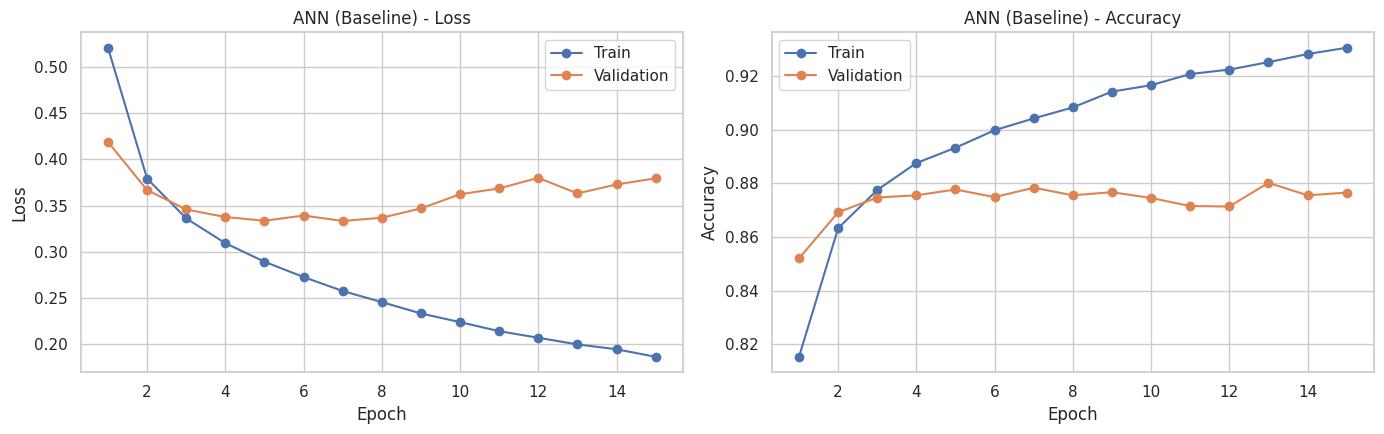

Epoch terakhir -> train acc: 0.9305 | val acc: 0.8765 | selisih acc: 0.0540
Epoch terakhir -> train loss: 0.1862 | val loss: 0.3795 | selisih loss: 0.1933
Val loss terendah pada epoch 7: 0.3333


In [18]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

plot_learning_curve(history_ann, "ANN (Baseline)")

In [19]:
# Lakukan prediksi pada test set. model.predict() menghasilkan probabilitas 10 kelas,
# ambil kelas dengan probabilitas terbesar menggunakan argmax(axis=1). Simpan hasil prediksi label.

proba_ann = model_ann.predict(X_test_ann, verbose=0)   # probabilitas 10 kelas, shape (10000, 10)
y_pred_ann = proba_ann.argmax(axis=1)                  # kelas dengan probabilitas terbesar

print("Bentuk output probabilitas:", proba_ann.shape)
print("10 prediksi pertama :", y_pred_ann[:10])
print("10 label asli       :", y_test[:10])
print(f"Akurasi test ANN    : {accuracy_score(y_test, y_pred_ann):.4f}")

Bentuk output probabilitas: (10000, 10)
10 prediksi pertama : [0 1 2 2 4 6 8 2 5 0]
10 label asli       : [0 1 2 2 3 2 8 6 5 0]
Akurasi test ANN    : 0.8807


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [20]:
# Definisikan arsitektur CNN sederhana menggunakan layers.Conv2D, layers.MaxPooling2D, layers.Flatten, dan layers.Dense.
# Gunakan keras.Input(shape=(28, 28, 1)) sebagai layer pertama.
# Tampilkan ringkasan model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1,
# lalu cocokkan dengan kolom "Output Shape" pada model.summary(). (padding="valid" berarti P = 0, padding="same" menjaga ukuran tetap)

tf.keras.utils.set_random_seed(SEED)

model_cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    # Blok konvolusi 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    # Blok konvolusi 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="CNN_Sederhana")

model_cnn.summary()

Model: "CNN_Sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Perhitungan manual ukuran output setiap layer konvolusi dan pooling

Rumus: $O = \dfrac{W - K + 2P}{S} + 1$, dengan $W$ = ukuran input, $K$ = ukuran kernel, $P$ = padding, $S$ = stride.

Conv2D di atas memakai `padding="valid"` (default) sehingga $P = 0$ dan stride $S = 1$. MaxPooling2D 2×2 memakai $K = 2$, $S = 2$, $P = 0$.

| Layer | Input | Perhitungan | Output | Jumlah parameter |
|---|---|---|---|---|
| Conv2D(32, 3×3) | 28×28×1 | (28 − 3 + 0)/1 + 1 = **26** | 26×26×32 | (3·3·1 + 1)·32 = **320** |
| MaxPooling2D(2×2) | 26×26×32 | (26 − 2 + 0)/2 + 1 = **13** | 13×13×32 | 0 |
| Conv2D(64, 3×3) | 13×13×32 | (13 − 3 + 0)/1 + 1 = **11** | 11×11×64 | (3·3·32 + 1)·64 = **18.496** |
| MaxPooling2D(2×2) | 11×11×64 | (11 − 2 + 0)/2 + 1 = 5,5 → dibulatkan ke bawah = **5** | 5×5×64 | 0 |
| Flatten | 5×5×64 | 5·5·64 | **1.600** | 0 |
| Dense(128) | 1.600 | – | 128 | (1.600 + 1)·128 = **204.928** |
| Dense(10) | 128 | – | 10 | (128 + 1)·10 = **1.290** |

Total parameter = 320 + 18.496 + 204.928 + 1.290 = **225.034**. Sel di bawah memverifikasi perhitungan manual ini terhadap `Output Shape` pada `model.summary()`.

In [21]:
def output_size(W, K, P=0, S=1):
    """Rumus ukuran output konvolusi / pooling: (W - K + 2P) / S + 1 (dibulatkan ke bawah)."""
    return (W - K + 2 * P) // S + 1

manual = {}
w = 28
w = output_size(w, K=3, P=0, S=1); manual["conv2d (1)"] = (w, w, 32)
w = output_size(w, K=2, P=0, S=2); manual["max_pooling2d (1)"] = (w, w, 32)
w = output_size(w, K=3, P=0, S=1); manual["conv2d (2)"] = (w, w, 64)
w = output_size(w, K=2, P=0, S=2); manual["max_pooling2d (2)"] = (w, w, 64)

rows = []
for (name, manual_shape), layer in zip(manual.items(), model_cnn.layers[:4]):
    keras_shape = tuple(layer.output.shape[1:])
    rows.append({"Layer": name, "Nama layer Keras": layer.name, "Hitung manual": manual_shape,
                 "Output Shape Keras": keras_shape, "Cocok": manual_shape == keras_shape})
display(pd.DataFrame(rows))

manual_params = (3*3*1 + 1)*32 + (3*3*32 + 1)*64 + (5*5*64 + 1)*128 + (128 + 1)*10
print(f"Total parameter hitung manual : {manual_params:,}")
print(f"Total parameter model.summary : {model_cnn.count_params():,}")
assert manual_params == model_cnn.count_params()

,Layer,Nama layer Keras,Hitung manual,Output Shape Keras,Cocok
0,conv2d (1),conv2d,"(26, 26, 32)","(26, 26, 32)",True
1,max_pooling2d (1),max_pooling2d,"(13, 13, 32)","(13, 13, 32)",True
2,conv2d (2),conv2d_1,"(11, 11, 64)","(11, 11, 64)",True
3,max_pooling2d (2),max_pooling2d_1,"(5, 5, 64)","(5, 5, 64)",True


Total parameter hitung manual : 225,034
Total parameter model.summary : 225,034


Epoch 1/15
422/422 - 16s - 38ms/step - accuracy: 0.8014 - loss: 0.5592 - val_accuracy: 0.8648 - val_loss: 0.3892
Epoch 2/15
422/422 - 8s - 18ms/step - accuracy: 0.8713 - loss: 0.3555 - val_accuracy: 0.8798 - val_loss: 0.3344
Epoch 3/15
422/422 - 2s - 5ms/step - accuracy: 0.8883 - loss: 0.3060 - val_accuracy: 0.8903 - val_loss: 0.3067
Epoch 4/15
422/422 - 2s - 4ms/step - accuracy: 0.9004 - loss: 0.2746 - val_accuracy: 0.8953 - val_loss: 0.2905
Epoch 5/15
422/422 - 2s - 4ms/step - accuracy: 0.9080 - loss: 0.2506 - val_accuracy: 0.9003 - val_loss: 0.2765
Epoch 6/15
422/422 - 2s - 4ms/step - accuracy: 0.9151 - loss: 0.2299 - val_accuracy: 0.9057 - val_loss: 0.2672
Epoch 7/15
422/422 - 2s - 4ms/step - accuracy: 0.9210 - loss: 0.2122 - val_accuracy: 0.9047 - val_loss: 0.2640
Epoch 8/15
422/422 - 2s - 5ms/step - accuracy: 0.9273 - loss: 0.1959 - val_accuracy: 0.9068 - val_loss: 0.2641
Epoch 9/15
422/422 - 2s - 6ms/step - accuracy: 0.9342 - loss: 0.1793 - val_accuracy: 0.9102 - val_loss: 0.259

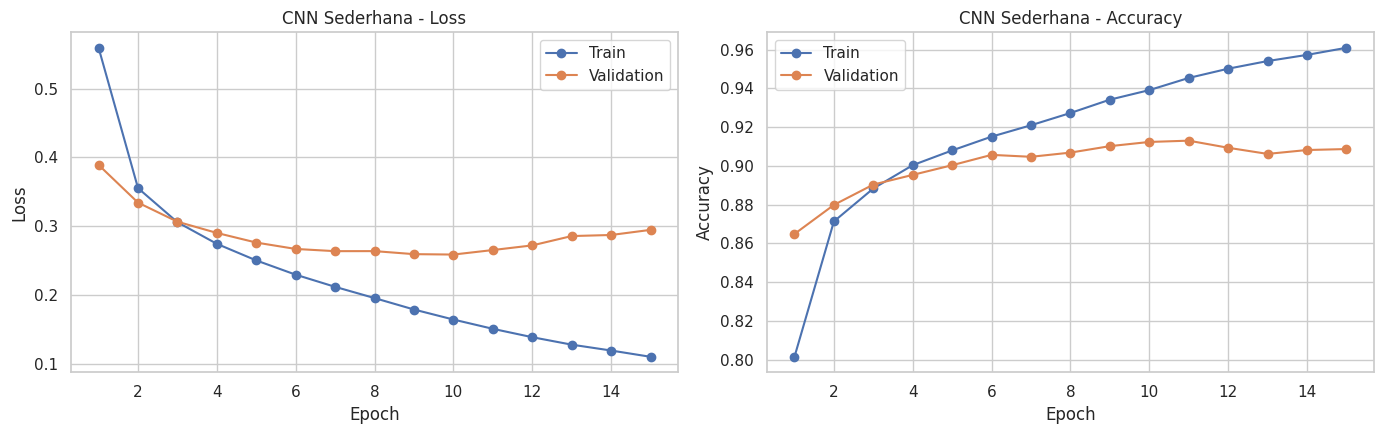

Epoch terakhir -> train acc: 0.9609 | val acc: 0.9087 | selisih acc: 0.0523
Epoch terakhir -> train loss: 0.1107 | val loss: 0.2949 | selisih loss: 0.1842
Val loss terendah pada epoch 10: 0.2591


In [22]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

history_cnn, time_cnn = compile_and_fit(model_cnn, X_train_cnn, y_train, X_val_cnn, y_val)
plot_learning_curve(history_cnn, "CNN Sederhana")

In [23]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

proba_cnn = model_cnn.predict(X_test_cnn, verbose=0)
y_pred_cnn = proba_cnn.argmax(axis=1)

print("10 prediksi pertama :", y_pred_cnn[:10])
print("10 label asli       :", y_test[:10])
print(f"Akurasi test CNN sederhana: {accuracy_score(y_test, y_pred_cnn):.4f}")

10 prediksi pertama : [0 1 2 6 3 6 8 6 5 0]
10 label asli       : [0 1 2 2 3 2 8 6 5 0]
Akurasi test CNN sederhana: 0.9135


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [24]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: Conv2D (tanpa activation) -> layers.BatchNormalization() -> layers.Activation("relu") -> MaxPooling2D.
# Tambahkan layers.Dropout(rate) sebelum layer output.
# Tampilkan ringkasan model beserta jumlah parameternya.

tf.keras.utils.set_random_seed(SEED)

DROPOUT_RATE = 0.5

model_cnn_bn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    # Blok konvolusi 1: Conv2D (tanpa activation) -> BatchNormalization -> ReLU -> MaxPooling
    layers.Conv2D(32, (3, 3)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    # Blok konvolusi 2
    layers.Conv2D(64, (3, 3)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(DROPOUT_RATE),          # Dropout sebelum layer output
    layers.Dense(10, activation="softmax"),
], name="CNN_BatchNorm_Dropout")

model_cnn_bn.summary()

Model: "CNN_BatchNorm_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/15
422/422 - 13s - 30ms/step - accuracy: 0.7786 - loss: 0.6173 - val_accuracy: 0.7287 - val_loss: 0.6616
Epoch 2/15
422/422 - 2s - 5ms/step - accuracy: 0.8485 - loss: 0.4273 - val_accuracy: 0.8745 - val_loss: 0.3443
Epoch 3/15
422/422 - 2s - 5ms/step - accuracy: 0.8639 - loss: 0.3787 - val_accuracy: 0.8867 - val_loss: 0.3110
Epoch 4/15
422/422 - 2s - 5ms/step - accuracy: 0.8748 - loss: 0.3465 - val_accuracy: 0.8958 - val_loss: 0.2854
Epoch 5/15
422/422 - 2s - 6ms/step - accuracy: 0.8846 - loss: 0.3229 - val_accuracy: 0.8952 - val_loss: 0.2891
Epoch 6/15
422/422 - 2s - 6ms/step - accuracy: 0.8889 - loss: 0.3097 - val_accuracy: 0.8998 - val_loss: 0.2781
Epoch 7/15
422/422 - 2s - 5ms/step - accuracy: 0.8945 - loss: 0.2921 - val_accuracy: 0.9012 - val_loss: 0.2709
Epoch 8/15
422/422 - 2s - 5ms/step - accuracy: 0.8989 - loss: 0.2765 - val_accuracy: 0.8972 - val_loss: 0.2835
Epoch 9/15
422/422 - 2s - 5ms/step - accuracy: 0.9024 - loss: 0.2673 - val_accuracy: 0.8900 - val_loss: 0.3035

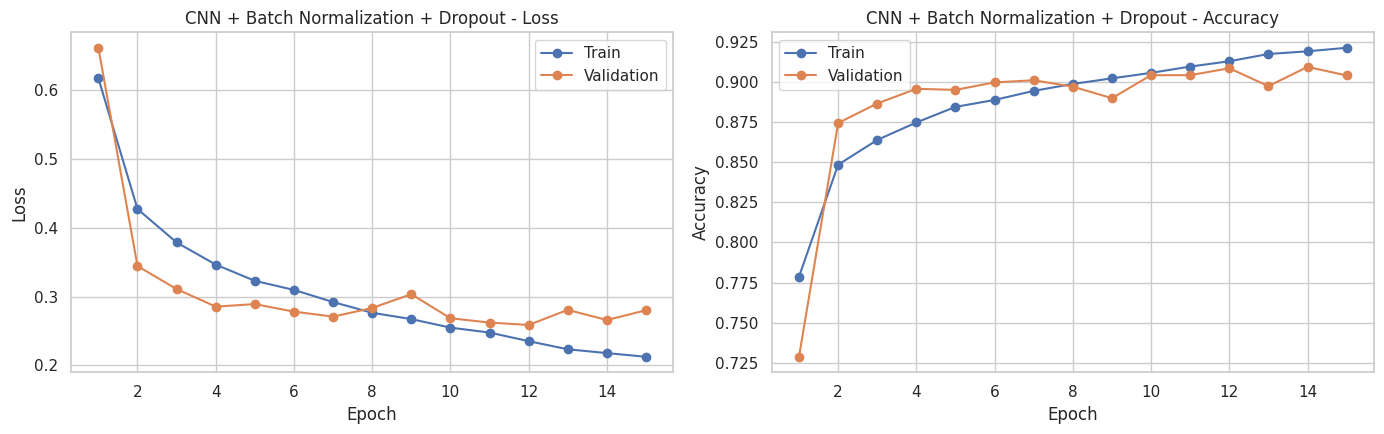

Epoch terakhir -> train acc: 0.9214 | val acc: 0.9042 | selisih acc: 0.0173
Epoch terakhir -> train loss: 0.2125 | val loss: 0.2801 | selisih loss: 0.0676
Val loss terendah pada epoch 12: 0.2588


In [25]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

history_cnn_bn, time_cnn_bn = compile_and_fit(model_cnn_bn, X_train_cnn, y_train, X_val_cnn, y_val)
plot_learning_curve(history_cnn_bn, "CNN + Batch Normalization + Dropout")

### Perbandingan learning curve ketiga model

Untuk memudahkan pengamatan selisih (gap) antara train dan validation, learning curve ketiga model ditampilkan berdampingan beserta tabel selisihnya pada epoch terakhir.

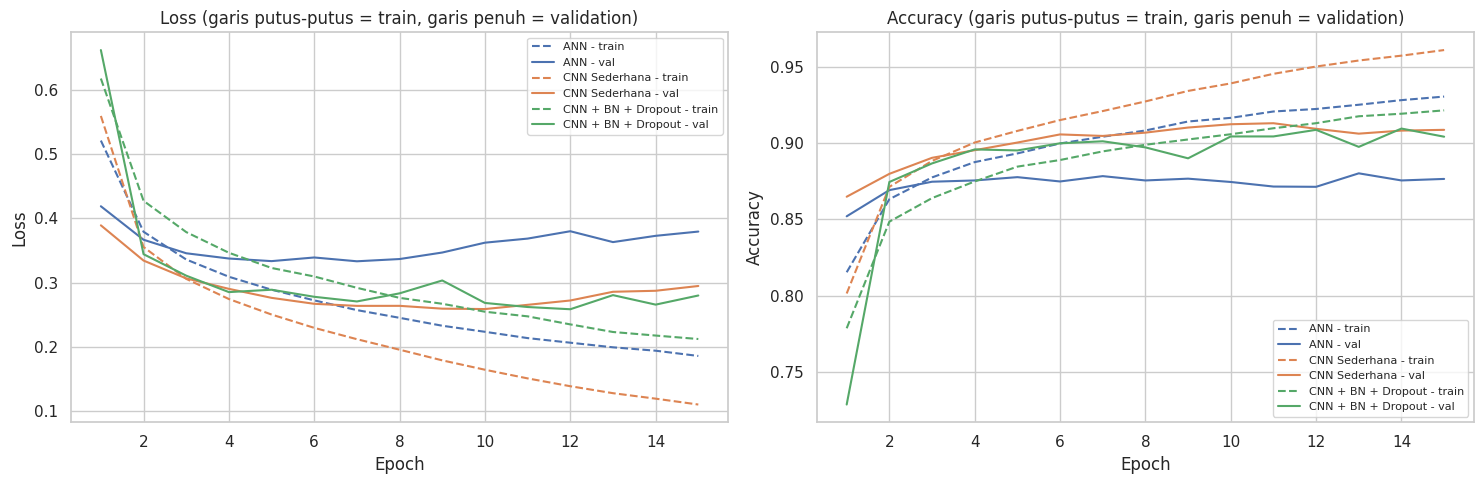

,Train Acc,Val Acc,Selisih Acc (train - val),Train Loss,Val Loss,Selisih Loss (val - train),Val Loss Terendah,Epoch Val Loss Terendah
Model,,,,,,,,
ANN,0.9305,0.8765,0.0540,0.1862,0.3795,0.1933,0.3333,7
CNN Sederhana,0.9609,0.9087,0.0523,0.1107,0.2949,0.1842,0.2591,10
CNN + BN + Dropout,0.9214,0.9042,0.0173,0.2125,0.2801,0.0676,0.2588,12


In [26]:
histories = {
    "ANN": history_ann,
    "CNN Sederhana": history_cnn,
    "CNN + BN + Dropout": history_cnn_bn,
}
colors = {"ANN": "#4C72B0", "CNN Sederhana": "#DD8452", "CNN + BN + Dropout": "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, hist in histories.items():
    h = hist.history
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], color=colors[name], linestyle="--", label=f"{name} - train")
    axes[0].plot(ep, h["val_loss"], color=colors[name], linestyle="-", label=f"{name} - val")
    axes[1].plot(ep, h["accuracy"], color=colors[name], linestyle="--", label=f"{name} - train")
    axes[1].plot(ep, h["val_accuracy"], color=colors[name], linestyle="-", label=f"{name} - val")
axes[0].set_title("Loss (garis putus-putus = train, garis penuh = validation)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(fontsize=8)
axes[1].set_title("Accuracy (garis putus-putus = train, garis penuh = validation)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

gap_df = pd.DataFrame([{
    "Model": name,
    "Train Acc": h.history["accuracy"][-1],
    "Val Acc": h.history["val_accuracy"][-1],
    "Selisih Acc (train - val)": h.history["accuracy"][-1] - h.history["val_accuracy"][-1],
    "Train Loss": h.history["loss"][-1],
    "Val Loss": h.history["val_loss"][-1],
    "Selisih Loss (val - train)": h.history["val_loss"][-1] - h.history["loss"][-1],
    "Val Loss Terendah": min(h.history["val_loss"]),
    "Epoch Val Loss Terendah": int(np.argmin(h.history["val_loss"])) + 1,
} for name, h in histories.items()]).set_index("Model")
display(gap_df.round(4))

In [27]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

proba_cnn_bn = model_cnn_bn.predict(X_test_cnn, verbose=0)
y_pred_cnn_bn = proba_cnn_bn.argmax(axis=1)

print("10 prediksi pertama :", y_pred_cnn_bn[:10])
print("10 label asli       :", y_test[:10])
print(f"Akurasi test CNN + BN + Dropout: {accuracy_score(y_test, y_pred_cnn_bn):.4f}")

10 prediksi pertama : [0 1 2 6 3 6 8 6 5 0]
10 label asli       : [0 1 2 2 3 2 8 6 5 0]
Akurasi test CNN + BN + Dropout: 0.9099


# 4. Evaluasi Model

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter,Val Accuracy (epoch akhir),Waktu Training (detik)
Model,,,,,,,
ANN,0.8807,0.8849,0.8807,0.8818,"235,146",0.8765,25.1
CNN Sederhana,0.9135,0.9143,0.9135,0.9136,"225,034",0.9087,50.0
CNN + BN + Dropout,0.9099,0.9115,0.9099,0.9099,"225,418",0.9042,44.4


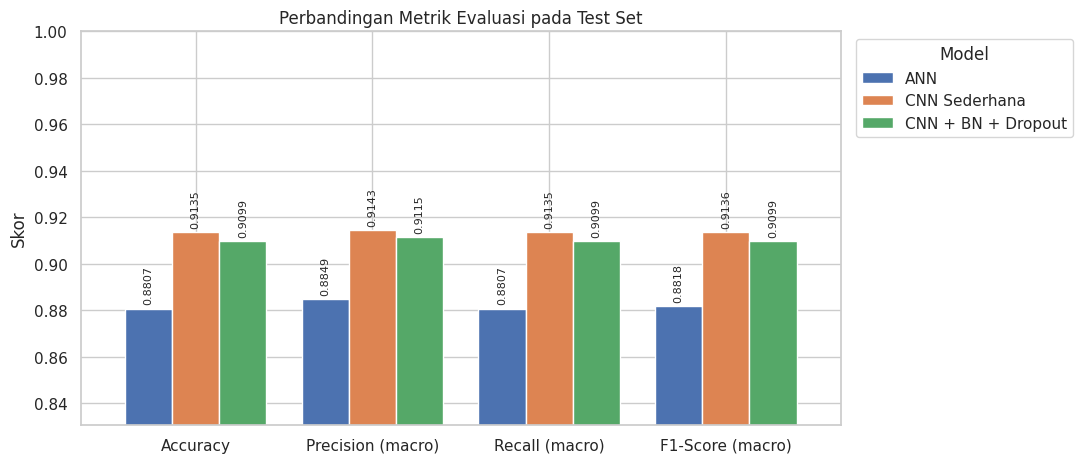

Model terbaik: CNN Sederhana (Accuracy = 0.9135, F1 macro = 0.9136)


In [28]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

experiments = {
    "ANN": {"model": model_ann, "y_pred": y_pred_ann, "proba": proba_ann, "history": history_ann, "time": time_ann, "X_test": X_test_ann},
    "CNN Sederhana": {"model": model_cnn, "y_pred": y_pred_cnn, "proba": proba_cnn, "history": history_cnn, "time": time_cnn, "X_test": X_test_cnn},
    "CNN + BN + Dropout": {"model": model_cnn_bn, "y_pred": y_pred_cnn_bn, "proba": proba_cnn_bn, "history": history_cnn_bn, "time": time_cnn_bn, "X_test": X_test_cnn},
}

rows = []
for name, e in experiments.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, e["y_pred"]),
        "Precision (macro)": precision_score(y_test, e["y_pred"], average="macro"),
        "Recall (macro)": recall_score(y_test, e["y_pred"], average="macro"),
        "F1-Score (macro)": f1_score(y_test, e["y_pred"], average="macro"),
        "Jumlah Parameter": e["model"].count_params(),
        "Val Accuracy (epoch akhir)": e["history"].history["val_accuracy"][-1],
        "Waktu Training (detik)": round(e["time"], 1),
    })
results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision (macro)": "{:.4f}", "Recall (macro)": "{:.4f}", "F1-Score (macro)": "{:.4f}",
    "Jumlah Parameter": "{:,}", "Val Accuracy (epoch akhir)": "{:.4f}", "Waktu Training (detik)": "{:.1f}",
}).highlight_max(subset=["Accuracy", "Precision (macro)", "Recall (macro)", "F1-Score (macro)"], color="#c6efce"))

# Visualisasi perbandingan metrik pada test set
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-Score (macro)"]
ax = results_df[metric_cols].T.plot(kind="bar", figsize=(11, 4.8), color=["#4C72B0", "#DD8452", "#55A868"], width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=8, rotation=90, padding=3)
lo = results_df[metric_cols].values.min()
plt.ylim(max(0, lo - 0.05), 1.0)
plt.title("Perbandingan Metrik Evaluasi pada Test Set")
plt.ylabel("Skor")
plt.xticks(rotation=0)
plt.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Model terbaik dipilih berdasarkan F1-Score (macro) pada test set
best_name = results_df["F1-Score (macro)"].idxmax()
best = experiments[best_name]
best_model, y_pred_best, proba_best, X_test_best = best["model"], best["y_pred"], best["proba"], best["X_test"]
print(f"Model terbaik: {best_name} (Accuracy = {results_df.loc[best_name, 'Accuracy']:.4f}, "
      f"F1 macro = {results_df.loc[best_name, 'F1-Score (macro)']:.4f})")

In [29]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

print(f"Classification report - {best_name}\n")
print(classification_report(y_test, y_pred_best, target_names=class_names, digits=4))

Classification report - CNN Sederhana

              precision    recall  f1-score   support

 T-shirt/top     0.8409    0.8670    0.8538      1000
     Trouser     0.9879    0.9830    0.9855      1000
    Pullover     0.8894    0.8360    0.8619      1000
       Dress     0.9430    0.8930    0.9173      1000
        Coat     0.8446    0.9020    0.8723      1000
      Sandal     0.9889    0.9800    0.9844      1000
       Shirt     0.7597    0.7650    0.7623      1000
     Sneaker     0.9500    0.9700    0.9599      1000
         Bag     0.9722    0.9790    0.9756      1000
  Ankle boot     0.9668    0.9600    0.9634      1000

    accuracy                         0.9135     10000
   macro avg     0.9143    0.9135    0.9136     10000
weighted avg     0.9143    0.9135    0.9136     10000



### Perbandingan F1-Score per kelas untuk ketiga model

,ANN,CNN Sederhana,CNN + BN + Dropout
T-shirt/top,0.8143,0.8538,0.8577
Trouser,0.9825,0.9855,0.9880
Pullover,0.8192,0.8619,0.8562
Dress,0.8850,0.9173,0.9330
Coat,0.8307,0.8723,0.8486
Sandal,0.9514,0.9844,0.9742
Shirt,0.7081,0.7623,0.7468
Sneaker,0.9224,0.9599,0.9525
Bag,0.9768,0.9756,0.9824
Ankle boot,0.9276,0.9634,0.9596


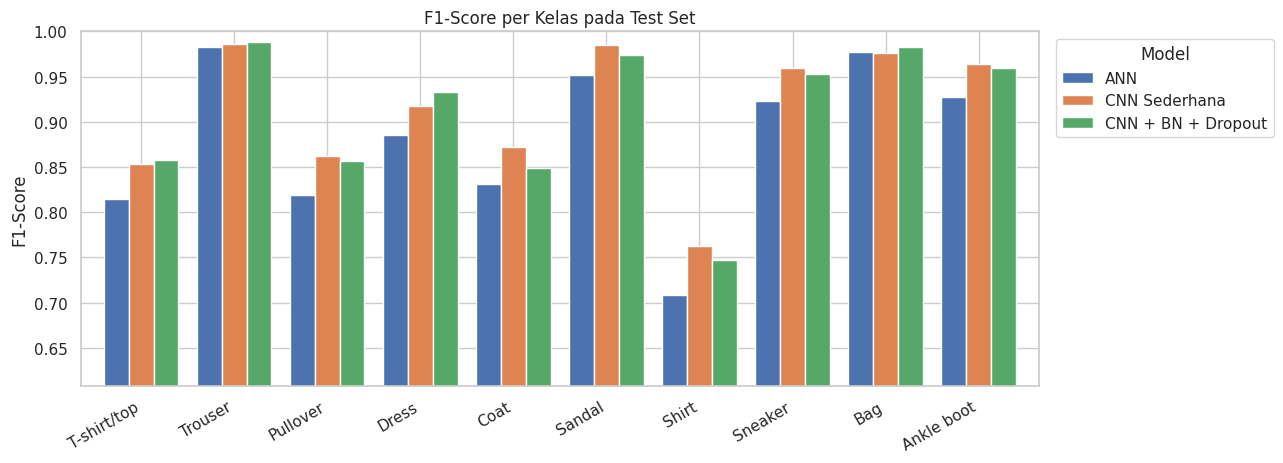

In [30]:
f1_per_class = pd.DataFrame({
    name: f1_score(y_test, e["y_pred"], average=None) for name, e in experiments.items()
}, index=class_names)
display(f1_per_class.round(4))

ax = f1_per_class.plot(kind="bar", figsize=(13, 4.8), color=["#4C72B0", "#DD8452", "#55A868"], width=0.8)
plt.title("F1-Score per Kelas pada Test Set")
plt.ylabel("F1-Score")
plt.ylim(max(0, f1_per_class.values.min() - 0.1), 1.0)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

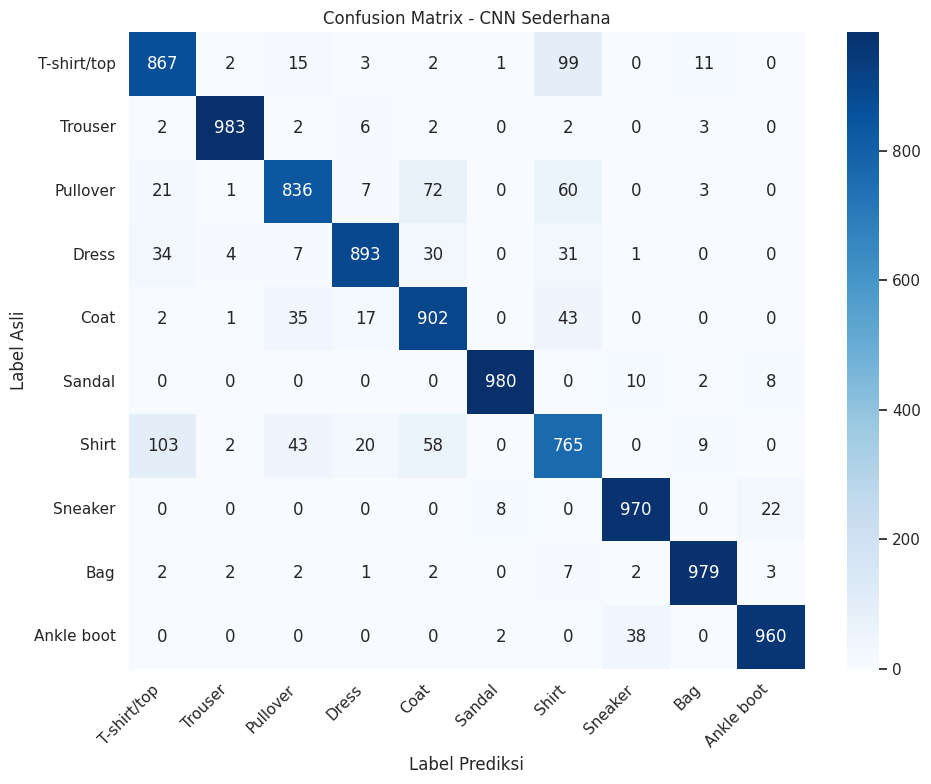

10 kesalahan terbanyak (label asli -> diprediksi sebagai):
  Shirt        -> T-shirt/top : 103 gambar
  T-shirt/top  -> Shirt       : 99 gambar
  Pullover     -> Coat        : 72 gambar
  Pullover     -> Shirt       : 60 gambar
  Shirt        -> Coat        : 58 gambar
  Shirt        -> Pullover    : 43 gambar
  Coat         -> Shirt       : 43 gambar
  Ankle boot   -> Sneaker     : 38 gambar
  Coat         -> Pullover    : 35 gambar
  Dress        -> T-shirt/top : 34 gambar

5 pasangan kelas yang paling sering tertukar (total dua arah):
  T-shirt/top  <-> Shirt       : 202 gambar
  Pullover     <-> Coat        : 107 gambar
  Pullover     <-> Shirt       : 103 gambar
  Coat         <-> Shirt       : 101 gambar
  Sneaker      <-> Ankle boot  : 60 gambar


In [31]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Asli")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pasangan kelas yang paling sering tertukar (elemen di luar diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
conf_pairs = [(cm_off[i, j], class_names[i], class_names[j]) for i in range(10) for j in range(10) if cm_off[i, j] > 0]
print("10 kesalahan terbanyak (label asli -> diprediksi sebagai):")
for n, a, b in sorted(conf_pairs, reverse=True)[:10]:
    print(f"  {a:12s} -> {b:12s}: {n} gambar")

# Total kesalahan dua arah untuk setiap pasangan kelas
sym = cm_off + cm_off.T
sym_pairs = [(sym[i, j], class_names[i], class_names[j]) for i in range(10) for j in range(i + 1, 10) if sym[i, j] > 0]
print("\n5 pasangan kelas yang paling sering tertukar (total dua arah):")
for n, a, b in sorted(sym_pairs, reverse=True)[:5]:
    print(f"  {a:12s} <-> {b:12s}: {n} gambar")

**Pasangan kelas yang paling sering tertukar:**

Berdasarkan confusion matrix model terbaik (CNN sederhana), kesalahan hampir seluruhnya terjadi di antara kelas pakaian atasan dan berpusat pada kelas **Shirt**:

| Pasangan kelas | Total tertukar (dua arah) | Rincian |
|---|---|---|
| T-shirt/top ↔ Shirt | 202 gambar | 103 Shirt diprediksi T-shirt/top, 99 T-shirt/top diprediksi Shirt |
| Pullover ↔ Coat | 107 gambar | 72 Pullover diprediksi Coat, 35 Coat diprediksi Pullover |
| Pullover ↔ Shirt | 103 gambar | 60 Pullover diprediksi Shirt, 43 Shirt diprediksi Pullover |
| Coat ↔ Shirt | 101 gambar | 58 Shirt diprediksi Coat, 43 Coat diprediksi Shirt |
| Sneaker ↔ Ankle boot | 60 gambar | 38 Ankle boot diprediksi Sneaker, 22 Sneaker diprediksi Ankle boot |

Pasangan yang paling sering tertukar adalah **T-shirt/top ↔ Shirt**, dengan kesalahan yang hampir sama besar pada kedua arah (103 dan 99 gambar). Tiga pasangan berikutnya melibatkan Pullover, Coat, dan Shirt, yaitu kelompok pakaian atasan berlengan panjang. Hasil ini sejalan dengan temuan EDA bahwa gambar rata-rata Coat, Pullover, dan Shirt saling berkorelasi di atas 0,94. Di luar pakaian atasan, satu-satunya pasangan yang cukup sering tertukar adalah Sneaker ↔ Ankle boot, yang juga muncul pada EDA (kelompok alas kaki berdekatan pada proyeksi PCA). Trouser, Bag, dan Sandal hampir tidak pernah tertukar dengan kelas lain.

Jumlah gambar yang salah diklasifikasikan: 865 dari 10000 (8.65%)


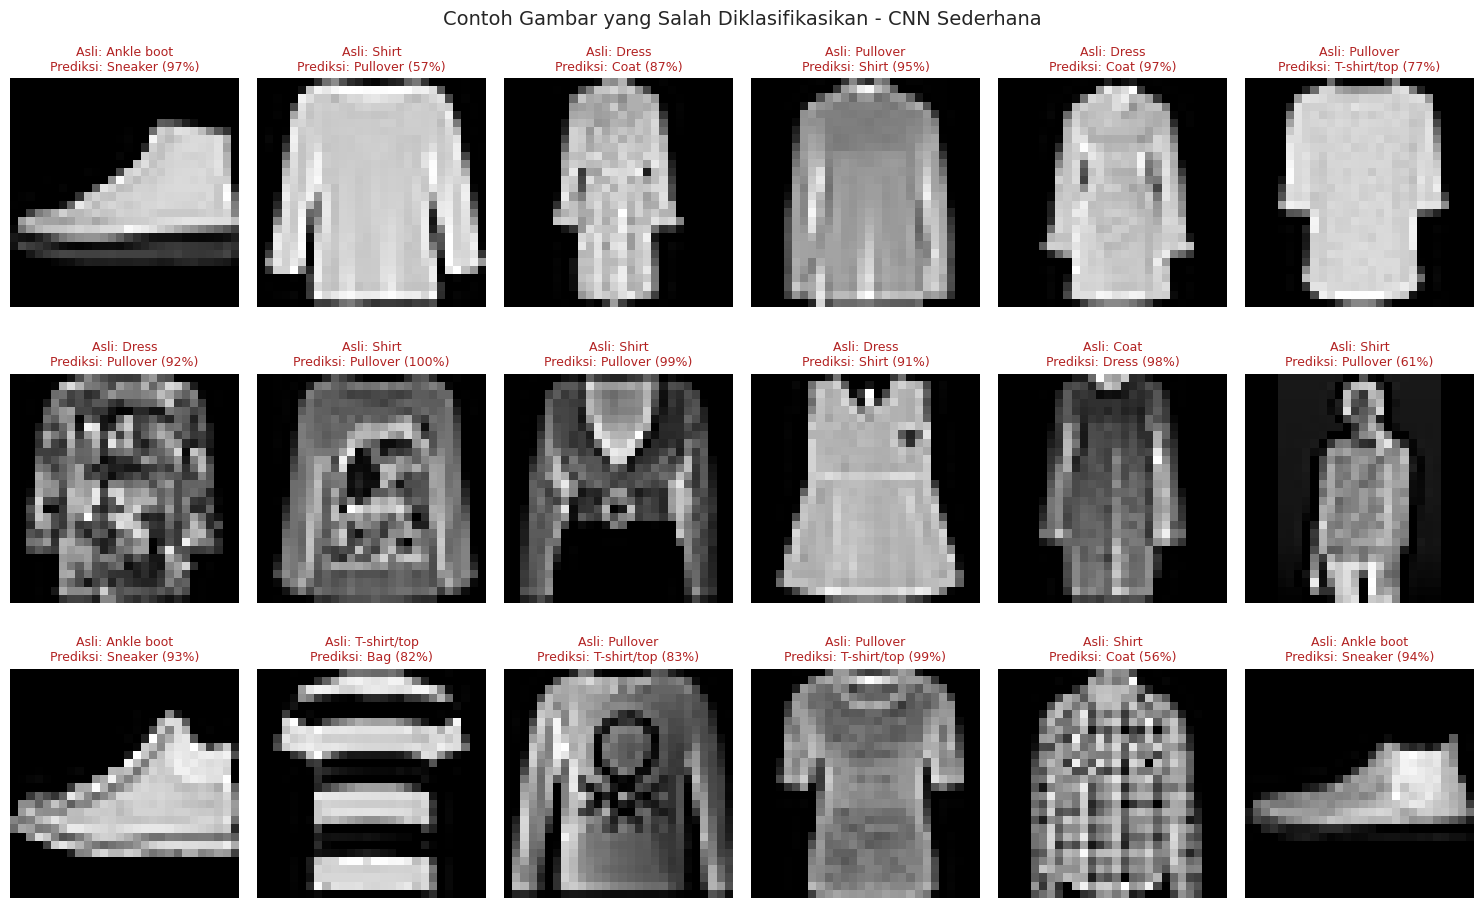

In [32]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

wrong_idx = np.where(y_pred_best != y_test)[0]
print(f"Jumlah gambar yang salah diklasifikasikan: {len(wrong_idx)} dari {len(y_test)} ({len(wrong_idx) / len(y_test) * 100:.2f}%)")

rng = np.random.default_rng(SEED)
show_idx = rng.choice(wrong_idx, size=min(18, len(wrong_idx)), replace=False)

fig, axes = plt.subplots(3, 6, figsize=(15, 9.5))
for ax, idx in zip(axes.ravel(), show_idx):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[idx]]}\nPrediksi: {class_names[y_pred_best[idx]]} ({proba_best[idx].max() * 100:.0f}%)",
                 fontsize=9, color="firebrick")
    ax.axis("off")
plt.suptitle(f"Contoh Gambar yang Salah Diklasifikasikan - {best_name}", fontsize=14)
plt.tight_layout(h_pad=2.0)
plt.show()

Model yang divisualisasikan: CNN Sederhana
Layer yang divisualisasikan: conv2d | output shape: (None, 26, 26, 32)
Bentuk feature map: (1, 26, 26, 32)


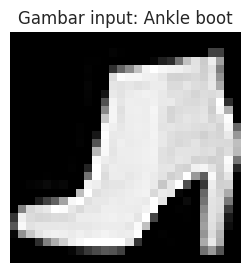

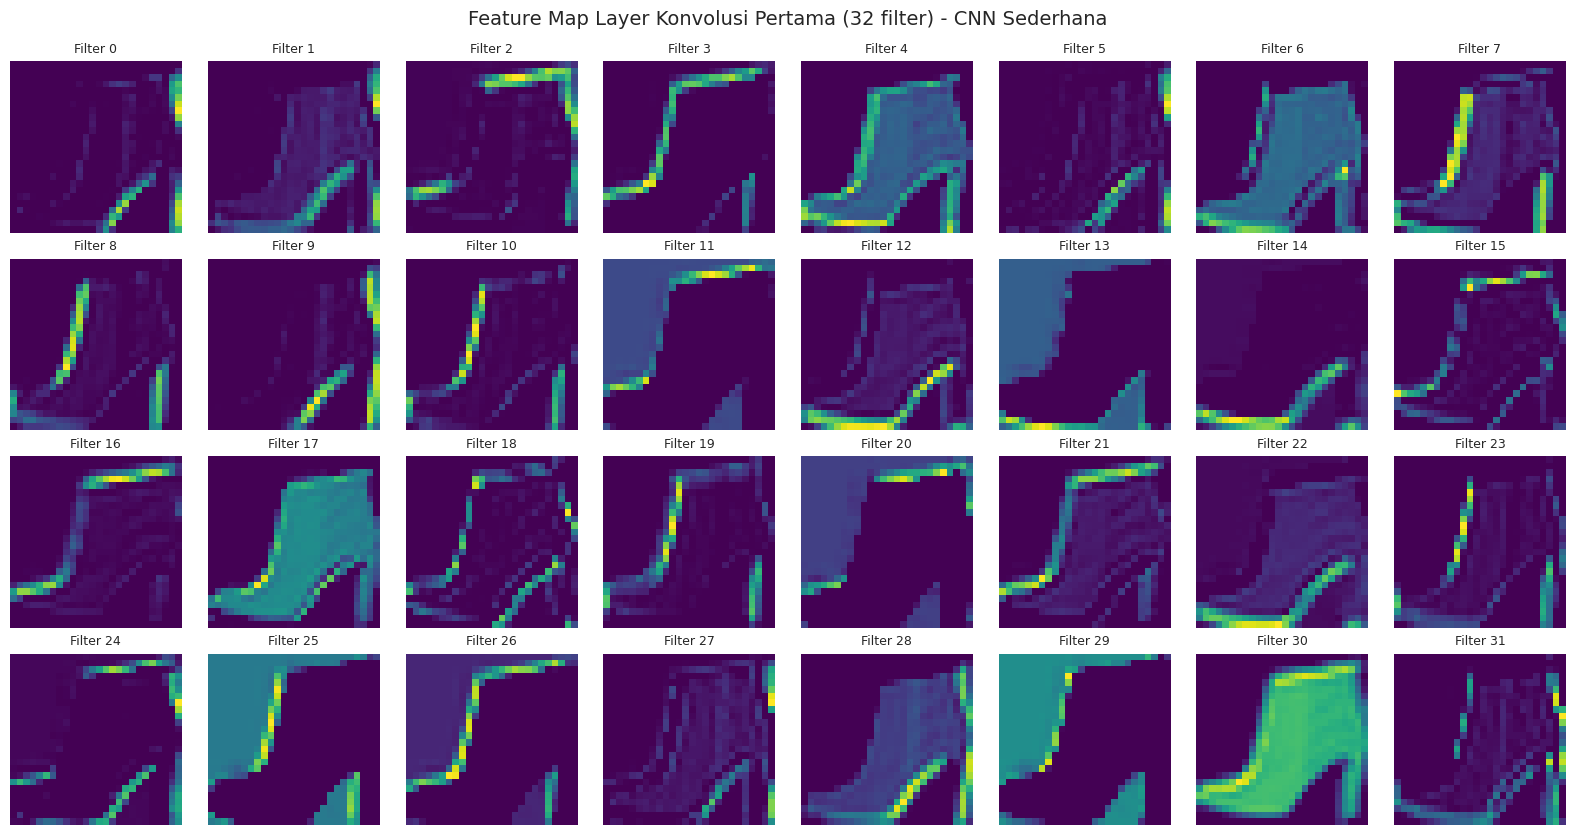

In [33]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Buat model baru yang output-nya adalah output layer konvolusi pertama:
#   feature_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
# lalu tampilkan setiap channel hasil feature_model.predict() sebagai gambar.
# Apa saja pola yang ditangkap oleh masing-masing filter?

# Feature map hanya ada pada model CNN. Jika model terbaik adalah ANN, gunakan CNN dengan F1 tertinggi.
fm_name = best_name if "CNN" in best_name else results_df.drop(index="ANN")["F1-Score (macro)"].idxmax()
fm_model = experiments[fm_name]["model"]

# Model baru yang output-nya adalah output layer konvolusi pertama
feature_model = keras.Model(inputs=fm_model.inputs, outputs=fm_model.layers[0].output)
print("Model yang divisualisasikan:", fm_name)
print("Layer yang divisualisasikan:", fm_model.layers[0].name, "| output shape:", feature_model.output.shape)

sample_idx = int(np.where(y_test == 9)[0][0])      # satu contoh gambar Ankle boot
sample_img = X_test_cnn[sample_idx:sample_idx + 1]
feature_maps = feature_model.predict(sample_img, verbose=0)
print("Bentuk feature map:", feature_maps.shape)

plt.figure(figsize=(3, 3))
plt.imshow(sample_img[0, :, :, 0], cmap="gray")
plt.title(f"Gambar input: {class_names[y_test[sample_idx]]}")
plt.axis("off")
plt.show()

n_filters = feature_maps.shape[-1]
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for i, ax in enumerate(axes.ravel()):
    if i < n_filters:
        ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
        ax.set_title(f"Filter {i}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Feature Map Layer Konvolusi Pertama ({n_filters} filter) - {fm_name}", fontsize=14)
plt.tight_layout()
plt.show()

Sebagai pembanding, feature map layer konvolusi pertama untuk gambar dari kelas yang sulit dibedakan (Shirt) juga ditampilkan, beserta bobot kernel 3×3 dari setiap filter.

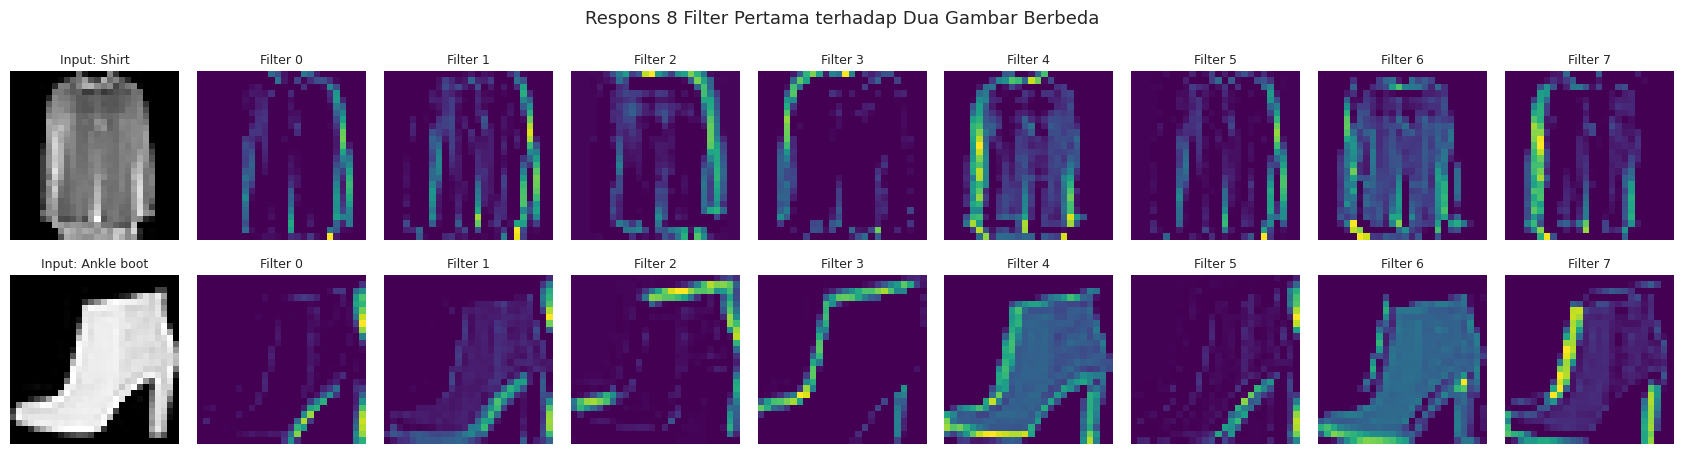

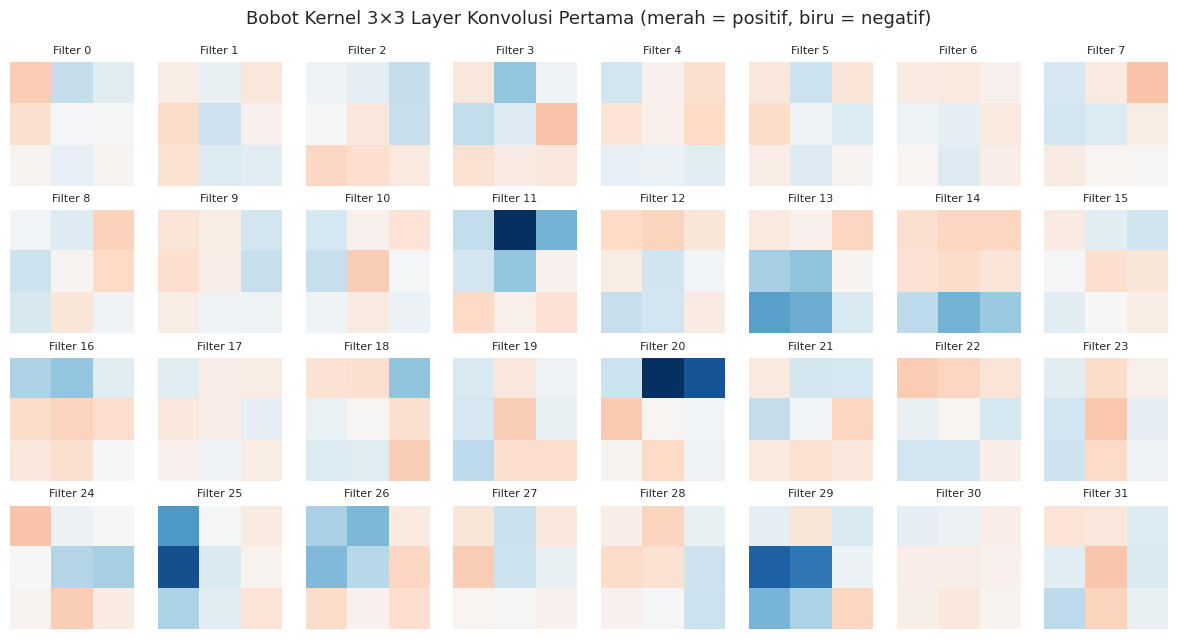

In [34]:
# Feature map untuk satu gambar Shirt
sample_idx2 = int(np.where(y_test == 6)[0][0])
fmap2 = feature_model.predict(X_test_cnn[sample_idx2:sample_idx2 + 1], verbose=0)

fig, axes = plt.subplots(2, 9, figsize=(17, 4.8))
axes[0, 0].imshow(X_test_cnn[sample_idx2, :, :, 0], cmap="gray"); axes[0, 0].set_title("Input: Shirt", fontsize=9)
axes[1, 0].imshow(X_test_cnn[sample_idx, :, :, 0], cmap="gray"); axes[1, 0].set_title("Input: Ankle boot", fontsize=9)
for k in range(8):
    axes[0, k + 1].imshow(fmap2[0, :, :, k], cmap="viridis"); axes[0, k + 1].set_title(f"Filter {k}", fontsize=9)
    axes[1, k + 1].imshow(feature_maps[0, :, :, k], cmap="viridis"); axes[1, k + 1].set_title(f"Filter {k}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Respons 8 Filter Pertama terhadap Dua Gambar Berbeda", fontsize=13)
plt.tight_layout(h_pad=1.5)
plt.show()

# Bobot kernel 3x3 setiap filter pada layer konvolusi pertama
kernels = fm_model.layers[0].get_weights()[0]      # shape (3, 3, 1, 32)
vmax = np.abs(kernels).max()
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(kernels[:, :, 0, i], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(f"Filter {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Bobot Kernel 3×3 Layer Konvolusi Pertama (merah = positif, biru = negatif)", fontsize=13)
plt.tight_layout()
plt.show()

**Pola yang ditangkap oleh filter:**

Layer konvolusi pertama memiliki 32 filter 3×3, sehingga satu gambar 28×28 diubah menjadi 32 feature map berukuran 26×26. Karena aktivasi ReLU sudah termasuk di dalam layer Conv2D, nilai negatif dipotong menjadi 0 (warna ungu gelap) dan hanya bagian gambar yang cocok dengan pola filter yang menyala. Dari visualisasi untuk gambar Ankle boot terlihat beberapa kelompok pola:

- **Detektor tepi vertikal.** Filter 7, 8, 10, 19, dan 23 hanya menyala pada sisi kiri batang sepatu, yaitu perubahan intensitas dari gelap ke terang secara mendatar.
- **Detektor tepi horizontal.** Filter 2, 3, 15, 16, 21, dan 24 menyala pada garis atas sepatu dan bagian atas ujung depan; filter 4 dan 13 menyala pada garis bawah sol.
- **Detektor tepi diagonal.** Filter 0, 1, 5, 9, 12, 14, 22, dan 28 merespons kuat pada garis miring antara sol dan hak sepatu.
- **Detektor area objek.** Filter 30, 17, dan 6 menyala pada hampir seluruh permukaan sepatu, sehingga menangkap **siluet/bentuk global** objek.
- **Detektor latar.** Filter 11, 13, 20, 25, dan 29 justru aktif pada area latar dan bernilai 0 pada objek, sehingga menandai batas luar objek dari sisi sebaliknya.
- **Filter dengan respons lemah.** Filter 27 dan 31 hampir tidak aktif pada gambar ini; filter seperti ini merespons pola yang tidak banyak muncul pada Ankle boot.

Pada gambar Shirt, filter yang sama merespons bagian yang berbeda: detektor tepi vertikal (misalnya filter 7) menyala pada sisi luar lengan, detektor tepi horizontal (filter 2 dan 3) menyala pada bahu dan kerah, dan filter 4 serta 6 menampilkan garis-garis lipatan kain di bagian badan. Jadi layer konvolusi pertama mempelajari **fitur tingkat rendah** (tepi berbagai orientasi, kontras, dan siluet) yang bersifat umum untuk semua kelas; filter yang sama digeser ke seluruh posisi gambar. Layer konvolusi kedua kemudian menggabungkan fitur-fitur ini menjadi pola yang lebih kompleks (kerah, lengan, sol) sebelum diklasifikasikan oleh layer Dense.

In [35]:
# Simpan model terbaik dengan model.save("model.keras").
# Model ini akan digunakan kembali pada tugas Deployment.

best_model.save("model.keras")
print(f"Model terbaik ({best_name}) disimpan sebagai model.keras ({os.path.getsize('model.keras') / 1024:.0f} KB)")

# Verifikasi: muat kembali model yang disimpan dan pastikan prediksinya identik
loaded_model = keras.models.load_model("model.keras")
y_pred_loaded = loaded_model.predict(X_test_best, verbose=0).argmax(axis=1)
print("Input shape model   :", loaded_model.input_shape)
print("Prediksi identik    :", bool((y_pred_loaded == y_pred_best).all()))
print(f"Akurasi test (model hasil load): {accuracy_score(y_test, y_pred_loaded):.4f}")

Model terbaik (CNN Sederhana) disimpan sebagai model.keras (2674 KB)
Input shape model   : (None, 28, 28, 1)
Prediksi identik    : True
Akurasi test (model hasil load): 0.9135


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

## 5.1 Perbandingan performa ketiga model

Ketiga model dilatih dengan pengaturan yang sama (Adam, learning rate 0,001, batch size 128, 15 epoch, 54.000 data train dan 6.000 data validation) dan dievaluasi pada 10.000 gambar test set.

| Model | Accuracy | Precision (macro) | Recall (macro) | F1-Score (macro) | Jumlah parameter |
|---|---|---|---|---|---|
| ANN (baseline) | 0,8807 | 0,8849 | 0,8807 | 0,8818 | 235.146 |
| CNN sederhana | **0,9135** | **0,9143** | **0,9135** | **0,9136** | 225.034 |
| CNN + BN + Dropout | 0,9099 | 0,9115 | 0,9099 | 0,9099 | 225.418 |

- **ANN → CNN sederhana:** accuracy naik 3,28 poin persentase (0,8807 → 0,9135), atau jumlah kesalahan turun dari 1.193 menjadi 865 gambar (berkurang sekitar 27%). Ini adalah lompatan performa terbesar dalam eksperimen.
- **CNN sederhana → CNN + BN + Dropout:** pada eksperimen ini penambahan Batch Normalization dan Dropout **tidak menaikkan** performa test. Accuracy justru turun 0,36 poin persentase (0,9135 → 0,9099) dan F1 macro turun 0,37 poin (0,9136 → 0,9099); kesalahan bertambah dari 865 menjadi 901 gambar. Selisih 36 gambar dari 10.000 ini kecil dan masih dalam rentang variasi antar-run, sehingga kedua CNN dapat dianggap setara pada metrik test. Perbedaan nyata keduanya terlihat pada learning curve (lihat 5.3).
- Karena kelas seimbang sempurna, accuracy sama dengan recall macro dan keempat metrik memberikan urutan model yang konsisten: **CNN sederhana > CNN + BN + Dropout > ANN**. Kedua CNN unggul sekitar 3 poin persentase atas ANN.

## 5.2 Kaitan performa dengan jumlah parameter dan cara model memproses gambar

Hal yang paling menarik adalah **ANN justru memiliki parameter paling banyak (235.146) tetapi performanya paling rendah**, sedangkan CNN sederhana dengan parameter lebih sedikit (225.034, sekitar 4% lebih kecil) unggul lebih dari 3 poin persentase. Jadi perbedaan performa bukan disebabkan oleh kapasitas (jumlah parameter), melainkan oleh **cara parameter tersebut digunakan**:

- **ANN** meratakan gambar menjadi vektor 784 nilai sehingga informasi posisi dua dimensi hilang. Setiap piksel diperlakukan sebagai fitur yang berdiri sendiri, dan piksel yang bertetangga tidak dianggap berhubungan. Sebanyak 200.960 dari 235.146 parameternya (85%) habis di layer Dense pertama hanya untuk menghubungkan setiap piksel ke 256 neuron. Model harus mempelajari pola yang sama secara terpisah untuk setiap posisi, sehingga kurang efisien dan sensitif terhadap pergeseran objek.
- **CNN** mempertahankan bentuk 28×28×1. Layer konvolusi menggeser filter 3×3 ke seluruh gambar (*weight sharing*), sehingga satu detektor tepi cukup dipelajari sekali dan berlaku di semua posisi. Dua layer konvolusi hanya membutuhkan 320 + 18.496 = 18.816 parameter (8% dari total) namun menghasilkan fitur yang jauh lebih informatif, seperti terlihat pada visualisasi feature map (detektor tepi vertikal, horizontal, diagonal, dan siluet). MaxPooling memperkecil ukuran (26→13 dan 11→5) dan membuat model lebih toleran terhadap pergeseran kecil. Layer Dense kemudian mengklasifikasi 1.600 fitur hasil ekstraksi, bukan piksel mentah.
- **CNN + BN + Dropout** hanya menambah 384 parameter Batch Normalization (192 dapat dilatih, 192 tidak dapat dilatih berupa moving mean dan variance), sedangkan Dropout tidak menambah parameter sama sekali. Kapasitasnya praktis sama dengan CNN sederhana, sehingga wajar bila akurasi test keduanya berdekatan; yang berubah adalah perilaku pelatihannya.

Keunggulan CNN paling besar justru pada kelas yang membutuhkan detail lokal. Dibanding ANN, F1-Score CNN sederhana naik pada Shirt (0,7081 → 0,7623), Pullover (0,8192 → 0,8619), Coat (0,8307 → 0,8723), T-shirt/top (0,8143 → 0,8538), Sneaker (0,9224 → 0,9599), Ankle boot (0,9276 → 0,9634), dan Sandal (0,9514 → 0,9844), sementara kelas yang sudah mudah hampir tidak berubah: Trouser (0,9825 → 0,9855) dan Bag (0,9768 → 0,9756).

Dari sisi biaya komputasi, operasi konvolusi lebih berat walaupun parameternya lebih sedikit: pada GPU T4, waktu training kedua CNN sekitar dua kali ANN (lihat kolom waktu training pada tabel evaluasi; angka pastinya bergantung pada perangkat yang digunakan).

## 5.3 Pengaruh Batch Normalization dan Dropout terhadap learning curve

| Model | Train acc | Val acc | Selisih acc | Train loss | Val loss | Selisih loss | Val loss terendah |
|---|---|---|---|---|---|---|---|
| ANN | 0,9305 | 0,8765 | 0,0540 | 0,1862 | 0,3795 | 0,1933 | 0,3333 (epoch 7) |
| CNN sederhana | 0,9609 | 0,9087 | 0,0523 | 0,1107 | 0,2949 | 0,1842 | 0,2591 (epoch 10) |
| CNN + BN + Dropout | 0,9214 | 0,9042 | 0,0173 | 0,2125 | 0,2801 | 0,0676 | 0,2588 (epoch 12) |

- **ANN dan CNN sederhana mengalami overfitting.** Pada ANN, validation loss mencapai titik terendah di epoch 7 (0,3333) lalu naik hingga 0,3795, dan validation accuracy mendatar di kisaran 0,87–0,88 sejak epoch 3, sementara train accuracy terus naik sampai 0,9305. Pada CNN sederhana pola yang sama muncul: validation loss terendah di epoch 10 (0,2591) lalu naik ke 0,2949, sedangkan train accuracy terus naik hingga 0,9609 dan train loss turun ke 0,1107. Setelah epoch 10, model hanya semakin menghafal data train tanpa perbaikan pada data baru.
- **Batch Normalization dan Dropout memperkecil selisih train–validation secara drastis.** Selisih accuracy turun dari 0,0523 menjadi 0,0173 (sekitar sepertiganya) dan selisih loss turun dari 0,1842 menjadi 0,0676. Validation loss pada epoch terakhir (0,2801) juga lebih rendah daripada CNN sederhana (0,2949), walaupun validation accuracy-nya sedikit di bawah (0,9042 dibanding 0,9087). Artinya model dengan regularisasi memberikan probabilitas yang lebih terkalibrasi dan tidak terlalu yakin pada prediksi yang salah.
- **Regularisasi mengurangi overfitting, tetapi tidak otomatis menaikkan akurasi.** Validation loss terendah kedua CNN hampir sama (0,2588 dan 0,2591). Dengan hanya 15 epoch, CNN sederhana belum cukup lama overfitting untuk merusak akurasi test-nya, sementara Dropout 0,5 memperlambat pembelajaran model ketiga. Itu sebabnya manfaat BN dan Dropout pada eksperimen ini tampak pada kestabilan generalisasi, bukan pada angka akurasi akhir.
- **Train accuracy menjadi lebih rendah, dan itu memang yang diharapkan.** Train accuracy CNN + BN + Dropout (0,9214) lebih rendah dari CNN sederhana (0,9609) karena Dropout mematikan 50% neuron secara acak pada setiap langkah training, sehingga model tidak dapat bergantung pada kombinasi neuron tertentu untuk menghafal data. Pada epoch 2 sampai 7, validation accuracy bahkan lebih tinggi daripada train accuracy, karena saat validasi Dropout tidak aktif dan seluruh neuron digunakan.
- **Efek samping Batch Normalization: kurva validation lebih berfluktuasi.** Pada epoch 1 validation accuracy hanya 0,7287 (di bawah train 0,7786) karena statistik moving mean/variance yang dipakai saat inferensi belum stabil, lalu melonjak ke 0,8745 pada epoch 2. Penurunan sesaat juga terlihat pada epoch 9 (0,8900) dan epoch 13 (0,8975). Kurva CNN sederhana lebih mulus, tetapi arah validation loss-nya memburuk.
- **Model ketiga belum konvergen sepenuhnya.** Pada epoch 15, train loss CNN + BN + Dropout masih turun (0,2125) dan selisihnya dengan validation masih kecil, sehingga model ini masih berpotensi membaik bila dilatih lebih lama, sedangkan dua model lain sudah melewati titik optimalnya.

## 5.4 Kelas-kelas yang sulit dibedakan

Berdasarkan classification report dan confusion matrix model terbaik (CNN sederhana):

- **Kelas termudah:** Trouser (F1 0,9855), Sandal (0,9844), Bag (0,9756), Ankle boot (0,9634), dan Sneaker (0,9599). Kelas-kelas ini memiliki siluet yang khas.
- **Kelas tersulit:** Shirt (F1 0,7623), jauh di bawah kelas lainnya, diikuti T-shirt/top (0,8538), Pullover (0,8619), dan Coat (0,8723). Dress berada di tengah (0,9173).
- **Shirt lemah pada dua sisi sekaligus.** Precision (0,7597) dan recall (0,7650) Shirt sama-sama rendah: sekitar 24% gambar yang ditebak Shirt sebenarnya kelas lain, dan sekitar 24% gambar Shirt ditebak sebagai kelas lain, terutama T-shirt/top (103 gambar), Coat (58), dan Pullover (43). Recall terendah berikutnya adalah Pullover (0,8360), yang banyak diprediksi sebagai Coat (72) dan Shirt (60).
- **Pasangan yang paling sering tertukar:** T-shirt/top ↔ Shirt (202 gambar), Pullover ↔ Coat (107), Pullover ↔ Shirt (103), Coat ↔ Shirt (101), dan Sneaker ↔ Ankle boot (60). Kelima pasangan ini mencakup 573 dari 865 kesalahan (66%).
- **Penyebabnya** konsisten dengan temuan EDA: gambar rata-rata Coat, Pullover, dan Shirt berkorelasi di atas 0,94 dan ketiganya bertumpuk pada proyeksi PCA. Pada resolusi 28×28 grayscale, ciri pembeda seperti kerah, kancing, resleting, dan jenis bahan hanya berukuran beberapa piksel atau hilang sama sekali. Contoh gambar yang salah diklasifikasikan memperlihatkan hal ini: banyak di antaranya sulit dibedakan bahkan oleh manusia, dan sebagian diprediksi dengan keyakinan sangat tinggi (misalnya Shirt diprediksi Pullover dengan keyakinan 100% dan Pullover diprediksi T-shirt/top dengan keyakinan 99%), yang menandakan adanya ambiguitas pada label itu sendiri.
- **Batch Normalization dan Dropout tidak menyelesaikan masalah ini.** Pada CNN + BN + Dropout, F1 Shirt justru turun (0,7623 → 0,7468), begitu pula Coat (0,8723 → 0,8486) dan Pullover (0,8619 → 0,8562). Peningkatan terjadi pada Dress (0,9173 → 0,9330), Bag (0,9756 → 0,9824), T-shirt/top (0,8538 → 0,8577), dan Trouser (0,9855 → 0,9880). Artinya kebingungan antar pakaian atasan lebih disebabkan oleh keterbatasan informasi pada gambar dan arsitektur yang masih dangkal, bukan oleh overfitting semata.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan

1. **CNN sederhana adalah model terbaik pada eksperimen ini** dengan accuracy 0,9135 dan F1-Score macro 0,9136 pada test set, diikuti CNN + Batch Normalization + Dropout (accuracy 0,9099; F1 0,9099) dan ANN (accuracy 0,8807; F1 0,8818). CNN sederhana disimpan sebagai `model.keras` untuk tugas Deployment.
2. **Arsitektur lebih menentukan daripada jumlah parameter.** ANN memiliki parameter paling banyak (235.146) tetapi performanya paling rendah, sedangkan CNN dengan 225.034 parameter unggul lebih dari 3 poin persentase. Konvolusi memanfaatkan struktur spasial gambar melalui weight sharing dan ekstraksi fitur lokal, sementara ANN kehilangan informasi tersebut karena gambar di-flatten.
3. **Batch Normalization dan Dropout memperbaiki generalisasi, tetapi tidak menaikkan akurasi test dalam 15 epoch.** Selisih accuracy train–validation turun dari 0,0523 menjadi 0,0173 dan validation loss akhir lebih rendah (0,2801 dibanding 0,2949), namun accuracy test 0,36 poin persentase di bawah CNN sederhana. Selisih antara kedua CNN kecil (36 gambar dari 10.000), sedangkan tanpa regularisasi ANN dan CNN sederhana mulai overfitting masing-masing sejak epoch 7 dan epoch 10.
4. **Kesalahan terkonsentrasi pada pakaian atasan.** Shirt adalah kelas tersulit (F1 0,7623) dan paling sering tertukar dengan T-shirt/top, Coat, dan Pullover, sedangkan Trouser, Sandal, Bag, Ankle boot, dan Sneaker dikenali dengan F1 di atas 0,95. Kemiripan ini sudah terlihat sejak EDA (korelasi gambar rata-rata di atas 0,94) dan terkonfirmasi pada confusion matrix.
5. **Layer konvolusi pertama mempelajari fitur tingkat rendah** berupa detektor tepi vertikal, horizontal, diagonal, serta detektor area objek dan latar, yang kemudian digabungkan oleh layer berikutnya menjadi fitur yang lebih kompleks.

## Saran

1. **Gunakan EarlyStopping dan ModelCheckpoint.** ANN dan CNN sederhana mencapai validation loss terbaik sebelum epoch terakhir, sehingga callback `EarlyStopping(monitor="val_loss", restore_best_weights=True)` akan menghemat waktu dan menyimpan bobot terbaik, bukan bobot epoch terakhir yang sudah overfitting.
2. **Latih CNN + BN + Dropout lebih lama dan atur dropout rate.** Model ini belum konvergen pada epoch 15. Menambah jumlah epoch (misalnya 30–50 dengan `ReduceLROnPlateau`) atau menurunkan dropout rate ke 0,3 berpotensi membuatnya melampaui CNN sederhana, karena ruang perbaikannya masih ada sementara CNN sederhana sudah overfitting.
3. **Ulangi eksperimen dengan beberapa random seed.** Selisih kedua CNN hanya 0,36 poin persentase, sehingga rata-rata dan standar deviasi dari beberapa run diperlukan untuk memastikan model mana yang benar-benar lebih baik.
4. **Terapkan data augmentation** (misalnya `RandomTranslation`, `RandomZoom`, dan `RandomFlip("horizontal")`) untuk menambah variasi data dan menekan overfitting pada CNN sederhana.
5. **Perdalam arsitektur.** Menambah blok konvolusi (misalnya dua Conv2D per blok ala VGG dengan `padding="same"`) atau memakai GlobalAveragePooling sebagai pengganti Flatten dapat meningkatkan kemampuan menangkap detail halus seperti kerah dan kancing yang membedakan Shirt, T-shirt/top, Coat, dan Pullover.
6. **Perhatikan perbedaan data saat deployment.** Model dilatih pada gambar 28×28 grayscale dengan objek terang di atas latar hitam dan posisi terpusat. Gambar dari pengguna harus melalui preprocessing yang sama (grayscale, pembalikan warna bila latar terang, resize ke 28×28, normalisasi 0–1), dan performa pada foto nyata kemungkinan lebih rendah daripada pada test set.